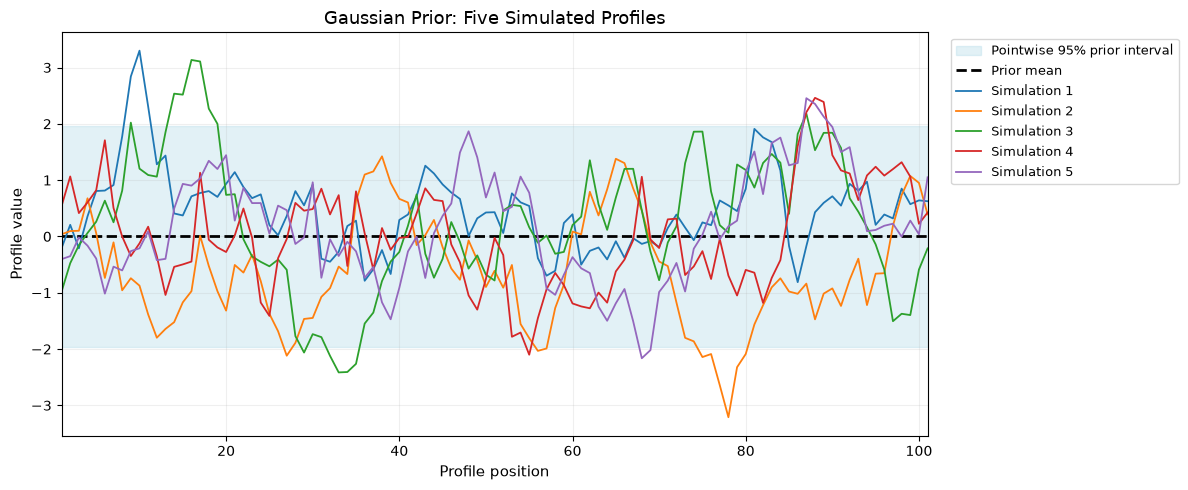

PART 1(b): PRIOR DISTRIBUTION
---------------------------------------------
Number of components: 101

Prior mean vector:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0.]

Prior covariance matrix shape:
(101, 101)

Prior variance (first component):
1.0

Prior standard deviation (first component):
1.0

Pointwise 95% prior credible interval:
[-1.96, 1.96]

Number of simulated profiles:
5

Shape of simulated profiles:
(5, 101)


In [1]:
# Part 1(b)


import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path



n = 101                  # Number of profile components
mu = 0.0                 # Prior mean
sigma_m2 = 1.0           # Prior variance
ell = 20.0               # Correlation length
sigma_eps2 = 0.04        # Measurement error variance



mu_m = np.full(n, mu)



# Create component indices
indices = np.arange(n)


distance = np.abs(
    indices[:, None] - indices[None, :]
)


Sigma_m = sigma_m2 * np.exp(
    -3 * distance / ell
)



prior_variance = np.diag(Sigma_m)

# Standard deviation = square root of variance
prior_sd = np.sqrt(prior_variance)

# Central 95% credible interval for a Gaussian distribution
lower_prior = mu_m - 1.96 * prior_sd
upper_prior = mu_m + 1.96 * prior_sd



# Set random seed for reproducible results
rng = np.random.default_rng(123)

# Each simulation contains 101 profile values
profiles = rng.multivariate_normal(
    mean=mu_m,
    cov=Sigma_m,
    size=5
)



# Profile positions: 1 to 101
x = np.arange(1, n + 1)


fig, ax = plt.subplots(figsize=(12, 5))


ax.fill_between(
    x,
    lower_prior,
    upper_prior,
    color="lightblue",
    alpha=0.35,
    label="Pointwise 95% prior interval"
)

# Plot the prior mean
ax.plot(
    x,
    mu_m,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Prior mean"
)

# Plot the five simulated profiles
for k in range(5):
    ax.plot(
        x,
        profiles[k],
        linewidth=1.3,
        label=f"Simulation {k + 1}"
    )


ax.set_xlabel("Profile position", fontsize=11)
ax.set_ylabel("Profile value", fontsize=11)


ax.set_title(
    "Gaussian Prior: Five Simulated Profiles",
    fontsize=13
)

# Set horizontal axis limits
ax.set_xlim(1, 101)


ax.grid(alpha=0.2)


ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=9,
    frameon=True
)


fig.tight_layout()



Path("figures").mkdir(exist_ok=True)

# Save the figure
fig.savefig(
    "figures/prior_profiles.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()




print("PART 1(b): PRIOR DISTRIBUTION")
print("-" * 45)

print("Number of components:", n)

print("\nPrior mean vector:")
print(mu_m)

print("\nPrior covariance matrix shape:")
print(Sigma_m.shape)

print("\nPrior variance (first component):")
print(prior_variance[0])

print("\nPrior standard deviation (first component):")
print(prior_sd[0])

print("\nPointwise 95% prior credible interval:")
print(f"[{lower_prior[0]:.2f}, {upper_prior[0]:.2f}]")

print("\nNumber of simulated profiles:")
print(profiles.shape[0])

print("\nShape of simulated profiles:")
print(profiles.shape)


Forward matrix shape: (101, 101)
Observed data shape: (101,)


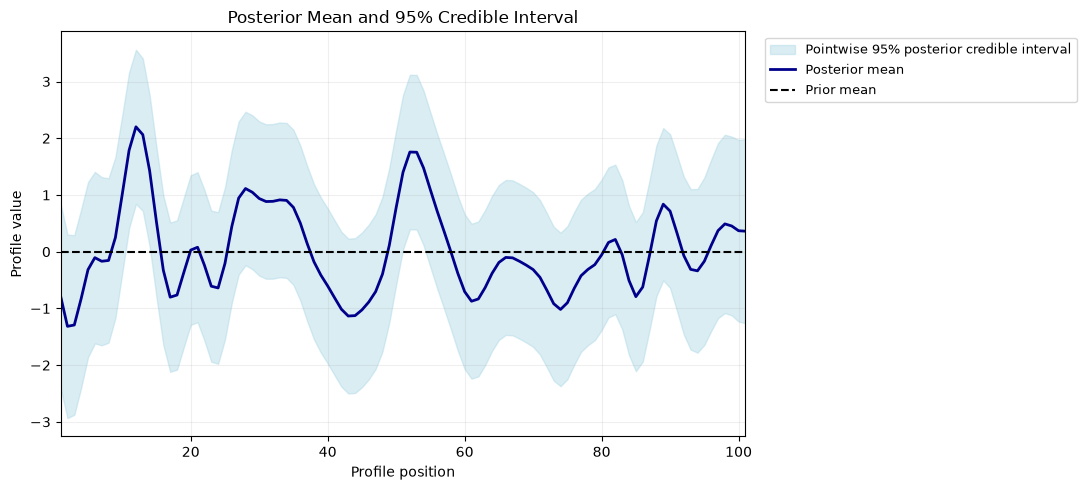

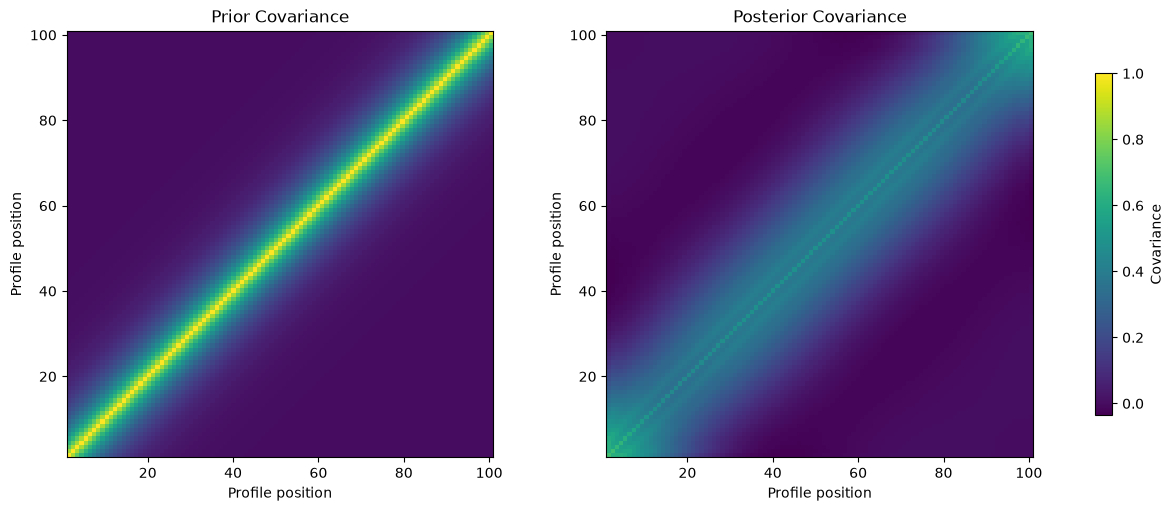


PART 1(c): POSTERIOR RESULTS
--------------------------------------------------
Number of profile components: 101

Average prior variance: 1.000000
Average posterior variance: 0.499473
Reduction in average marginal variance: 50.05%

Minimum posterior standard deviation: 0.670697
Maximum posterior standard deviation: 0.828832

Minimum posterior mean: -1.315832
Maximum posterior mean: 2.201565

Saved figures:
figures/posterior_profile.png
figures/covariance_comparison.png


In [2]:
# Part 1(c)

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


n = 101
mu = 0.0
sigma_m2 = 1.0
ell = 20.0
sigma_eps2 = 0.04

# Folder for saving figures
Path("figures").mkdir(exist_ok=True)


A = np.loadtxt("A.txt")
d = np.loadtxt("seis00.txt").reshape(-1)

# Check dimensions
assert A.shape == (n, n), f"Unexpected A shape: {A.shape}"
assert d.shape == (n,), f"Unexpected d shape: {d.shape}"

print("Forward matrix shape:", A.shape)
print("Observed data shape:", d.shape)



# Prior mean vector: all components have mean zero
mu_m = np.full(n, mu)

# Distance matrix |i-j|
indices = np.arange(n)
distance = np.abs(indices[:, None] - indices[None, :])

# Exponential prior covariance
Sigma_m = sigma_m2 * np.exp(-3 * distance / ell)



# Calculate the covariance of observed data


# Sigma_d = A @ Sigma_m @ A.T + sigma_eps2 * I
Sigma_d = A @ Sigma_m @ A.T + sigma_eps2 * np.eye(n)


# Calculate the posterior mean

# K = Sigma_m @ A.T @ inverse(Sigma_d)


K = np.linalg.solve(Sigma_d, A @ Sigma_m).T

# Difference between observed and prior-predicted data
residual = d - A @ mu_m

# Posterior mean
mu_post = mu_m + K @ residual


# posterior covariance


# Sigma_post = Sigma_m - K @ A @ Sigma_m
Sigma_post = Sigma_m - K @ A @ Sigma_m

# Remove small numerical asymmetry due to rounding
Sigma_post = 0.5 * (Sigma_post + Sigma_post.T)


# pointwise 95% posterior credible intervals

# Posterior marginal variances
posterior_variance = np.diag(Sigma_post)

# Posterior standard deviations
posterior_sd = np.sqrt(np.maximum(posterior_variance, 0))

# Pointwise 95% credible intervals
lower_post = mu_post - 1.96 * posterior_sd
upper_post = mu_post + 1.96 * posterior_sd


# Plot posterior mean and credible interval


x = np.arange(1, n + 1)

fig, ax = plt.subplots(figsize=(11, 5))

ax.fill_between(
    x,
    lower_post,
    upper_post,
    color="lightblue",
    alpha=0.45,
    label="Pointwise 95% posterior credible interval"
)

ax.plot(
    x,
    mu_post,
    color="darkblue",
    linewidth=2,
    label="Posterior mean"
)


ax.plot(
    x,
    mu_m,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Prior mean"
)

ax.set_xlabel("Profile position")
ax.set_ylabel("Profile value")
ax.set_title("Posterior Mean and 95% Credible Interval")

ax.set_xlim(1, n)
ax.grid(alpha=0.2)


ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=9
)

fig.tight_layout()

fig.savefig(
    "figures/posterior_profile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Compare prior and posterior covariance matrices

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    constrained_layout=True
)


vmin = min(Sigma_m.min(), Sigma_post.min())
vmax = max(Sigma_m.max(), Sigma_post.max())

im1 = axes[0].imshow(
    Sigma_m,
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    origin="lower",
    extent=[1, n, 1, n],
    aspect="equal"
)

axes[0].set_title("Prior Covariance")
axes[0].set_xlabel("Profile position")
axes[0].set_ylabel("Profile position")

im2 = axes[1].imshow(
    Sigma_post,
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    origin="lower",
    extent=[1, n, 1, n],
    aspect="equal"
)

axes[1].set_title("Posterior Covariance")
axes[1].set_xlabel("Profile position")
axes[1].set_ylabel("Profile position")

# One shared colorbar
fig.colorbar(
    im2,
    ax=axes,
    shrink=0.8,
    label="Covariance"
)

fig.savefig(
    "figures/covariance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Calculate uncertainty reduction

# Average marginal variance
avg_prior_variance = np.mean(np.diag(Sigma_m))
avg_posterior_variance = np.mean(np.diag(Sigma_post))

# Percentage reduction
variance_reduction = (
    1 - avg_posterior_variance / avg_prior_variance
) * 100




print("\nPART 1(c): POSTERIOR RESULTS")
print("-" * 50)

print(f"Number of profile components: {n}")

print(f"\nAverage prior variance: "
      f"{avg_prior_variance:.6f}")

print(f"Average posterior variance: "
      f"{avg_posterior_variance:.6f}")

print(f"Reduction in average marginal variance: "
      f"{variance_reduction:.2f}%")

print(f"\nMinimum posterior standard deviation: "
      f"{posterior_sd.min():.6f}")

print(f"Maximum posterior standard deviation: "
      f"{posterior_sd.max():.6f}")

print(f"\nMinimum posterior mean: "
      f"{mu_post.min():.6f}")

print(f"Maximum posterior mean: "
      f"{mu_post.max():.6f}")

print("\nSaved figures:")
print("figures/posterior_profile.png")
print("figures/covariance_comparison.png")


QUESTION 1(d):
Forward matrix shape: (101, 101)
Observed data shape: (101,)
Number of profile components: 101

Posterior distribution calculated.
Posterior mean shape: (101,)
Posterior covariance shape: (101, 101)

Posterior samples shape: (100, 101)
POSTERIOR VOLUME RESULTS
Number of simulations : 100
Threshold             : -1.0
Posterior mean        : 8.978531
Posterior median      : 6.914061
Posterior SD          : 7.738994
Minimum volume        : 0.506870
Maximum volume        : 36.006618


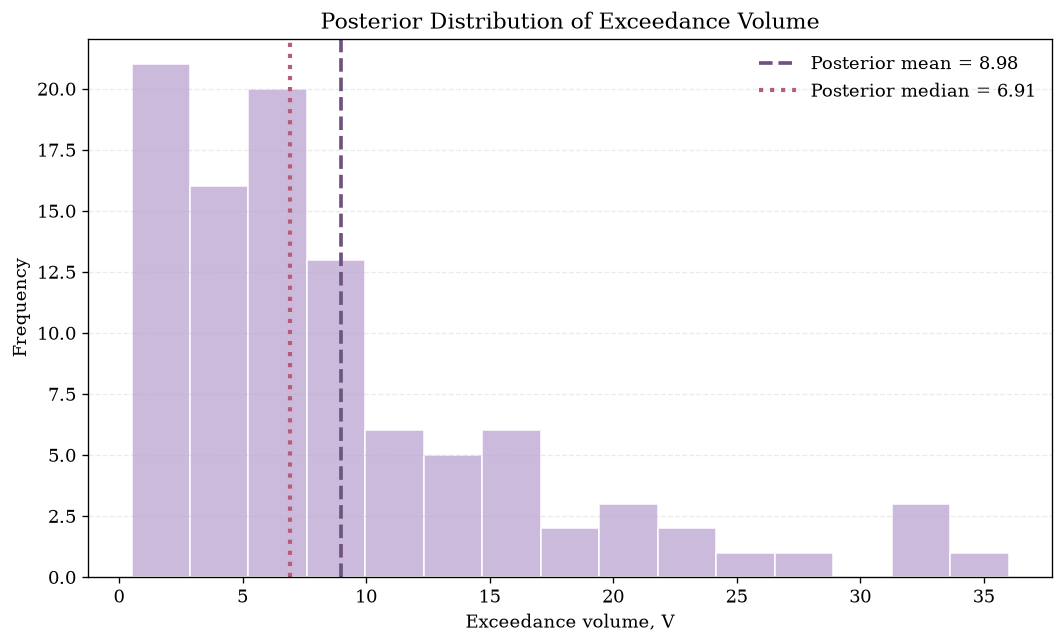

In [3]:
# 1(d)

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

SEED = 42
B = 100                 # Number of posterior simulations
c = -1.0                # Threshold

A_FILE = "A.txt"
DATA_FILE = "seis00.txt"

OUTPUT_DIR = Path("Figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(SEED)


A = np.loadtxt(A_FILE)
d = np.loadtxt(DATA_FILE).reshape(-1)

n = len(d)

assert A.shape == (n, n), (
    f"Expected A to have shape {(n, n)}, "
    f"but found {A.shape}"
)


print("QUESTION 1(d):")

print(f"Forward matrix shape: {A.shape}")
print(f"Observed data shape: {d.shape}")
print(f"Number of profile components: {n}")


mu = 0.0
sigma_m2 = 1.0
ell = 20.0
sigma_e2 = 0.04

# Prior mean vector
mu_m = np.full(n, mu)

# Prior covariance matrix
indices = np.arange(n)

distance = np.abs(
    indices[:, None] - indices[None, :]
)

Sigma_m = sigma_m2 * np.exp(
    -3.0 * distance / ell
)

# Measurement error covariance
Sigma_e = sigma_e2 * np.eye(n)

# Gaussian Posterior

# Data covariance
Sigma_d = A @ Sigma_m @ A.T + Sigma_e

# Cross-covariance
Sigma_md = Sigma_m @ A.T

# Posterior mean:
# mu_post = mu_m + Sigma_m A^T Sigma_d^(-1)
#                    (d - A mu_m)

innovation = d - A @ mu_m

mu_post = mu_m + Sigma_md @ np.linalg.solve(
    Sigma_d,
    innovation
)

# Posterior covariance:
# Sigma_post = Sigma_m
#              - Sigma_m A^T Sigma_d^(-1) A Sigma_m

Sigma_post = Sigma_m - Sigma_md @ np.linalg.solve(
    Sigma_d,
    A @ Sigma_m
)

# Ensure numerical symmetry
Sigma_post = 0.5 * (Sigma_post + Sigma_post.T)

print("\nPosterior distribution calculated.")
print(f"Posterior mean shape: {mu_post.shape}")
print(f"Posterior covariance shape: {Sigma_post.shape}")

# Generate 100 Independent Posterior Profiles

posterior_samples = rng.multivariate_normal(
    mean=mu_post,
    cov=Sigma_post,
    size=B,
    method="cholesky"
)

# Shape: (100, 101)
print(f"\nPosterior samples shape: {posterior_samples.shape}")

# Exceedance Volume for Each Profile

# V(m) = sum_i |m_i - c| I(m_i < c)
#
# Equivalent:
# V(m) = sum_i max(c - m_i, 0)
#
# For c = -1:
# V(m) = sum_i max(-1 - m_i, 0)

volumes = np.sum(
    np.maximum(c - posterior_samples, 0.0),
    axis=1
)

assert len(volumes) == B

# Posterior Summary Statistics

volume_mean = np.mean(volumes)
volume_median = np.median(volumes)

# Sample standard deviation (denominator B - 1)
volume_sd = np.std(volumes, ddof=1)


print("POSTERIOR VOLUME RESULTS")


print(f"Number of simulations : {B}")
print(f"Threshold             : {c:.1f}")
print(f"Posterior mean        : {volume_mean:.6f}")
print(f"Posterior median      : {volume_median:.6f}")
print(f"Posterior SD          : {volume_sd:.6f}")
print(f"Minimum volume        : {np.min(volumes):.6f}")
print(f"Maximum volume        : {np.max(volumes):.6f}")

# Histogram of Posterior Volumes

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 120,
    "savefig.dpi": 300
})

fig, ax = plt.subplots(figsize=(9, 5.5))

# Histogram
ax.hist(
    volumes,
    bins=15,
    color="#C6B3D9",
    edgecolor="white",
    alpha=0.90
)

# Posterior mean
ax.axvline(
    volume_mean,
    color="#6E527F",
    linestyle="--",
    linewidth=2.2,
    label=f"Posterior mean = {volume_mean:.2f}"
)

# Posterior median
ax.axvline(
    volume_median,
    color="#B65E78",
    linestyle=":",
    linewidth=2.5,
    label=f"Posterior median = {volume_median:.2f}"
)

ax.set_xlabel("Exceedance volume, V")
ax.set_ylabel("Frequency")

ax.set_title(
    "Posterior Distribution of Exceedance Volume"
)

ax.legend(frameon=False)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)



plt.tight_layout()

# Save figures
fig.savefig(
    OUTPUT_DIR / "Q1d_Posterior_Volume_Histogram.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Q1d_Posterior_Volume_Histogram.pdf",
    bbox_inches="tight"
)

plt.show()



np.savetxt(
    "Q1d_Posterior_Volumes.txt",
    volumes,
    fmt="%.12f",
    header="100 posterior exceedance volumes"
)



QUESTION 1(e)
Number of posterior simulations: 100

POSTERIOR PERCENTILE ESTIMATES
P10 (10th percentile): 1.946168
P90 (90th percentile): 19.673312

BINOMIAL CONFIDENCE INTERVAL FOR P10
-----------------------------------------------------------------
Binomial distribution: Binomial(100, 0.10)
Lower order-statistic rank: 5
Upper order-statistic rank: 17
Lower endpoint: 1.045381
Upper endpoint: 2.450462
95% confidence interval: [1.045381, 2.450462]
Actual coverage probability: 0.955690
Actual coverage percentage: 95.5690%
Lower-tail error probability: 0.023711
Upper-tail error probability: 0.020599


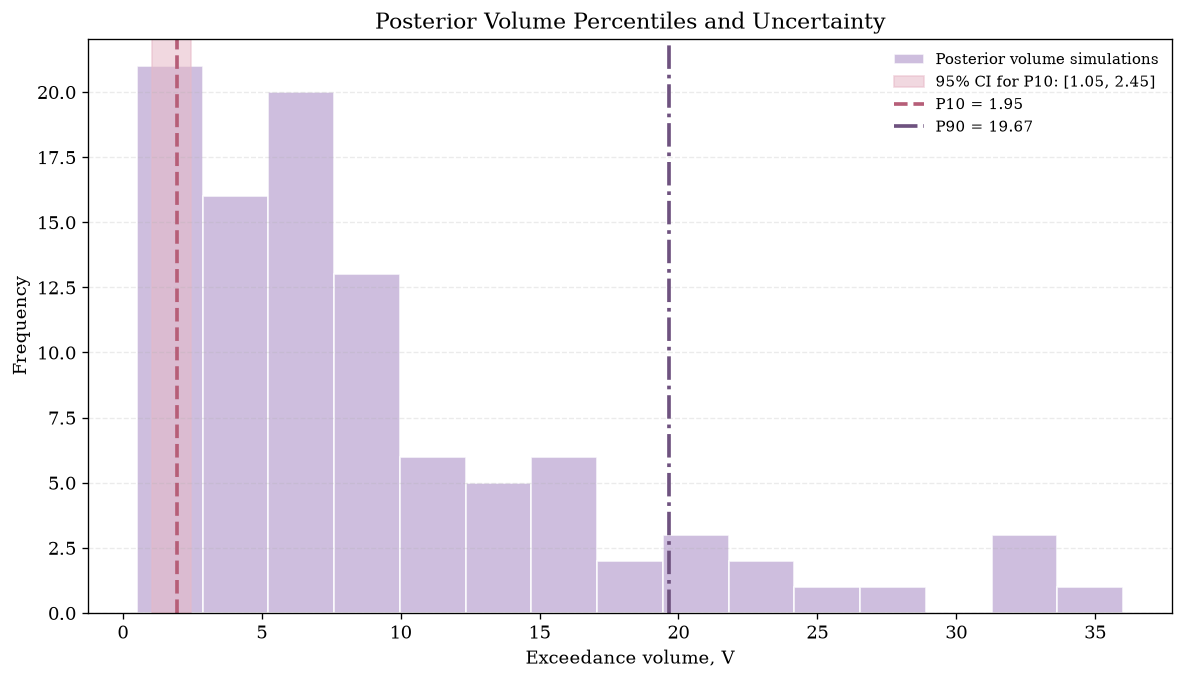

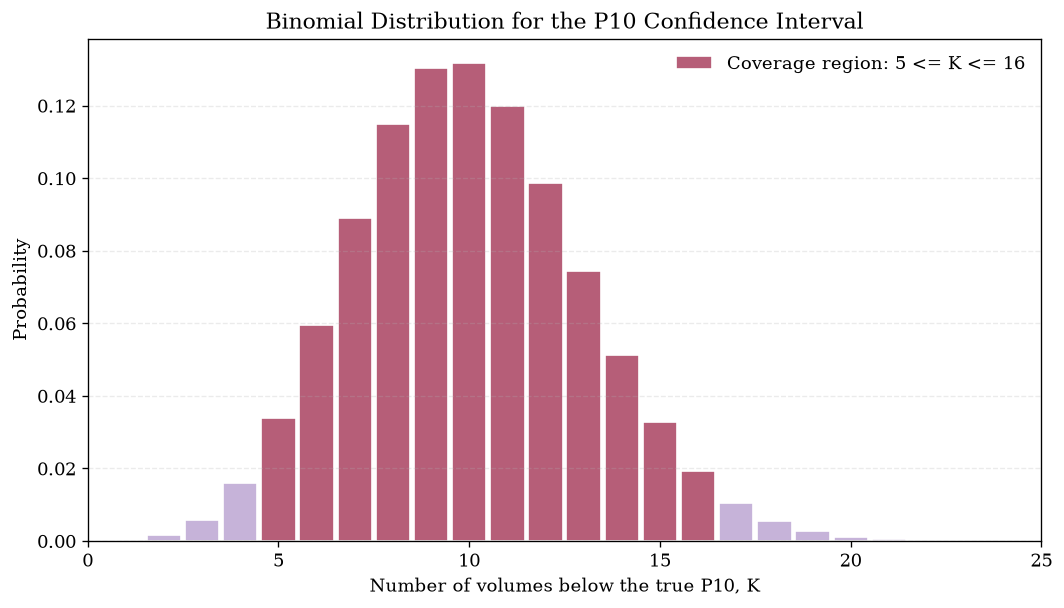

QUESTION 1(e): RESULTS
P10                  = 1.946168
P90                  = 19.673312
95% CI for P10       = [1.045381, 2.450462]
CI order statistics  = V_(5) to V_(17)
Binomial coverage    = 95.5690%

Figures saved in: C:\Users\natab7804\Documents\STK9021 Code\figures


In [4]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom
from pathlib import Path

VOLUME_FILE = Path("Q1d_Posterior_Volumes.txt")

OUTPUT_DIR = Path("Figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

B_EXPECTED = 100
p = 0.10
confidence_level = 0.95

if not VOLUME_FILE.exists():
    raise FileNotFoundError(
        f"Could not find {VOLUME_FILE}. Run Question 1(d) first."
    )

volumes = np.loadtxt(VOLUME_FILE).reshape(-1)

B = len(volumes)

if B != B_EXPECTED:
    raise ValueError(
        f"Expected {B_EXPECTED} volumes, found {B}."
    )

if not np.all(np.isfinite(volumes)):
    raise ValueError("Volumes contain invalid values.")

if np.any(volumes < 0):
    raise ValueError("Exceedance volumes cannot be negative.")

sorted_volumes = np.sort(volumes)


print("QUESTION 1(e)")

print(f"Number of posterior simulations: {B}")

P10 = np.percentile(volumes, 10, method="linear")
P90 = np.percentile(volumes, 90, method="linear")

print("\nPOSTERIOR PERCENTILE ESTIMATES")

print(f"P10 (10th percentile): {P10:.6f}")
print(f"P90 (90th percentile): {P90:.6f}")

candidates = []

for r in range(1, B + 1):
    for s in range(r + 1, B + 1):

        coverage = (
            binom.cdf(s - 1, B, p)
            - binom.cdf(r - 1, B, p)
        )

        if coverage >= confidence_level:

            lower_tail = binom.cdf(r - 1, B, p)
            upper_tail = binom.sf(s - 1, B, p)

            candidates.append((
                s - r,
                abs(lower_tail - upper_tail),
                r,
                s,
                coverage
            ))

if not candidates:
    raise RuntimeError(
        "No suitable confidence interval found."
    )

_, _, r, s, coverage = min(candidates)

ci_lower = sorted_volumes[r - 1]
ci_upper = sorted_volumes[s - 1]

lower_tail = binom.cdf(r - 1, B, p)
upper_tail = binom.sf(s - 1, B, p)

print("\nBINOMIAL CONFIDENCE INTERVAL FOR P10")
print("-" * 65)

print(f"Binomial distribution: Binomial({B}, {p:.2f})")
print(f"Lower order-statistic rank: {r}")
print(f"Upper order-statistic rank: {s}")

print(f"Lower endpoint: {ci_lower:.6f}")
print(f"Upper endpoint: {ci_upper:.6f}")

print(
    f"95% confidence interval: "
    f"[{ci_lower:.6f}, {ci_upper:.6f}]"
)

print(f"Actual coverage probability: {coverage:.6f}")
print(f"Actual coverage percentage: {coverage * 100:.4f}%")
print(f"Lower-tail error probability: {lower_tail:.6f}")
print(f"Upper-tail error probability: {upper_tail:.6f}")

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 120,
    "savefig.dpi": 300
})

fig, ax = plt.subplots(figsize=(10, 5.8))

ax.hist(
    volumes,
    bins=15,
    color="#C6B3D9",
    edgecolor="white",
    alpha=0.85,
    label="Posterior volume simulations"
)

ax.axvspan(
    ci_lower,
    ci_upper,
    color="#E7B9C7",
    alpha=0.55,
    label=(
        f"95% CI for P10: "
        f"[{ci_lower:.2f}, {ci_upper:.2f}]"
    )
)

ax.axvline(
    P10,
    color="#B65E78",
    linestyle="--",
    linewidth=2.2,
    label=f"P10 = {P10:.2f}"
)

ax.axvline(
    P90,
    color="#6E527F",
    linestyle="-.",
    linewidth=2.2,
    label=f"P90 = {P90:.2f}"
)

ax.set_title(
    "Posterior Volume Percentiles and Uncertainty"
)

ax.set_xlabel("Exceedance volume, V")
ax.set_ylabel("Frequency")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="upper right"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Q1e_Posterior_Percentiles.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Q1e_Posterior_Percentiles.pdf",
    bbox_inches="tight"
)

plt.show()

k_values = np.arange(B + 1)

probabilities = binom.pmf(k_values, B, p)

fig2, ax2 = plt.subplots(figsize=(9, 5.2))

ax2.bar(
    k_values,
    probabilities,
    color="#C6B3D9",
    edgecolor="white",
    width=0.9
)

mask = (k_values >= r) & (k_values <= s - 1)

ax2.bar(
    k_values[mask],
    probabilities[mask],
    color="#B65E78",
    edgecolor="white",
    width=0.9,
    label=f"Coverage region: {r} <= K <= {s - 1}"
)

ax2.set_xlim(0, 25)

ax2.set_xlabel(
    "Number of volumes below the true P10, K"
)

ax2.set_ylabel("Probability")

ax2.set_title(
    "Binomial Distribution for the P10 Confidence Interval"
)

ax2.legend(frameon=False)

ax2.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

fig2.tight_layout()

fig2.savefig(
    OUTPUT_DIR / "Q1e_Binomial_Coverage.png",
    dpi=300,
    bbox_inches="tight"
)

fig2.savefig(
    OUTPUT_DIR / "Q1e_Binomial_Coverage.pdf",
    bbox_inches="tight"
)

plt.show()

results = np.array([
    [P10, P90, ci_lower, ci_upper, coverage]
])

np.savetxt(
    "Q1e_Percentile_Results.txt",
    results,
    fmt="%.10f",
    header="P10 P90 CI_lower CI_upper Coverage"
)


print("QUESTION 1(e): RESULTS")


print(f"P10                  = {P10:.6f}")
print(f"P90                  = {P90:.6f}")

print(
    f"95% CI for P10       = "
    f"[{ci_lower:.6f}, {ci_upper:.6f}]"
)

print(f"CI order statistics  = V_({r}) to V_({s})")
print(f"Binomial coverage    = {coverage * 100:.4f}%")

print("\nFigures saved in:", OUTPUT_DIR.resolve())



QUESTION 1(f):
Number of observations: 101

Observed lag-one correlation: 0.832694646

PERMUTATION TEST RESULTS
Number of permutations: 1000
Observed statistic: 0.832694646
Extreme permutations: 0
Two-sided p-value: 0.000999001
Significance level: 0.05

Decision: Reject H0
The seismic observations provide evidence against exchangeability.


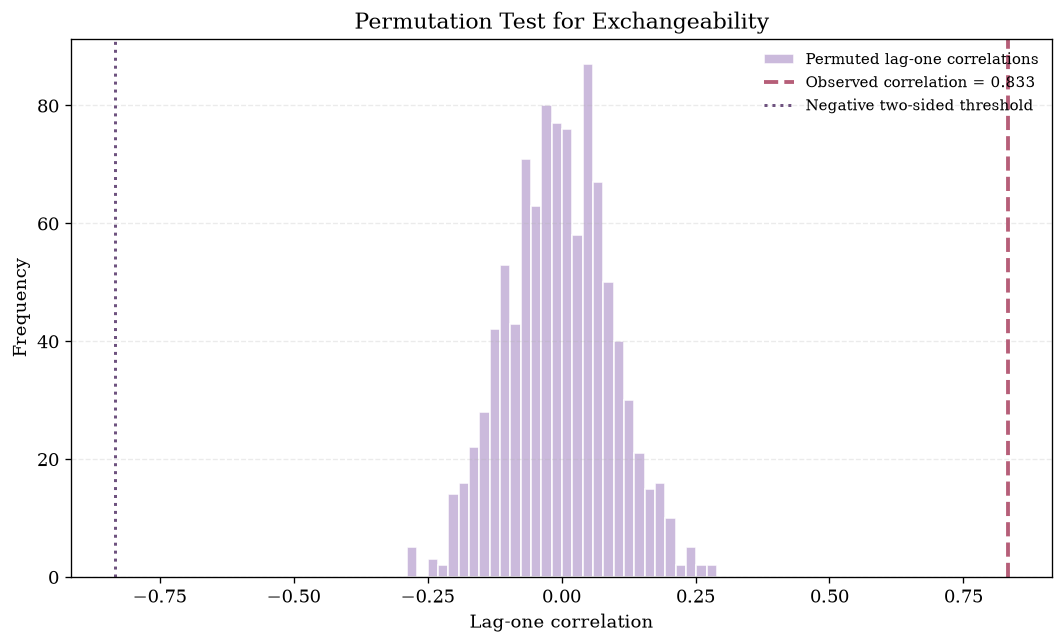

In [5]:
# 1(f) 

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


DATA_FILE = "seis00.txt"

B = 1000
SEED = 42
alpha = 0.05

OUTPUT_DIR = Path("Figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(SEED)



d = np.loadtxt(DATA_FILE).reshape(-1)

if not np.all(np.isfinite(d)):
    raise ValueError("The data contain non-finite values.")

n = len(d)


print("QUESTION 1(f):")

print(f"Number of observations: {n}")



def lag_one_correlation(x):
    return np.corrcoef(x[:-1], x[1:])[0, 1]

T_obs = lag_one_correlation(d)

print(f"\nObserved lag-one correlation: {T_obs:.9f}")



T_perm = np.empty(B)

for b in range(B):

    d_permuted = rng.permutation(d)

    T_perm[b] = lag_one_correlation(d_permuted)



extreme_count = np.sum(
    np.abs(T_perm) >= np.abs(T_obs)
)



p_value = (extreme_count + 1) / (B + 1)

print("\nPERMUTATION TEST RESULTS")


print(f"Number of permutations: {B}")
print(f"Observed statistic: {T_obs:.9f}")
print(f"Extreme permutations: {extreme_count}")
print(f"Two-sided p-value: {p_value:.9f}")
print(f"Significance level: {alpha:.2f}")

if p_value < alpha:
    decision = "Reject H0"
    interpretation = (
        "The seismic observations provide evidence "
        "against exchangeability."
    )
else:
    decision = "Do not reject H0"
    interpretation = (
        "Insufficient evidence to reject exchangeability."
    )

print(f"\nDecision: {decision}")
print(interpretation)



plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 120,
    "savefig.dpi": 300
})

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.hist(
    T_perm,
    bins=30,
    color="#C6B3D9",
    edgecolor="white",
    alpha=0.90,
    label="Permuted lag-one correlations"
)

ax.axvline(
    T_obs,
    color="#B65E78",
    linestyle="--",
    linewidth=2.3,
    label=f"Observed correlation = {T_obs:.3f}"
)

# Mark negative counterpart for two-sided test
ax.axvline(
    -T_obs,
    color="#6E527F",
    linestyle=":",
    linewidth=1.8,
    label="Negative two-sided threshold"
)

ax.set_xlabel("Lag-one correlation")
ax.set_ylabel("Frequency")

ax.set_title(
    "Permutation Test for Exchangeability"
)

ax.legend(frameon=False, fontsize=9)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)



plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Q1f_Permutation_Test.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Q1f_Permutation_Test.pdf",
    bbox_inches="tight"
)

plt.show()


np.savetxt(
    "Q1f_Permutation_Statistics.txt",
    T_perm,
    fmt="%.12f",
    header="Lag-one correlations from 1000 permutations"
)




Number of admissible pairs: 751
DATASET: seis01
Joint MAP top T: 41
Joint MAP base B: 46
Joint MAP thickness: 6
Marginal MAP top: 41
Marginal MAP base: 46
Marginal MAP thickness: 6
Maximum joint posterior probability: 0.986741


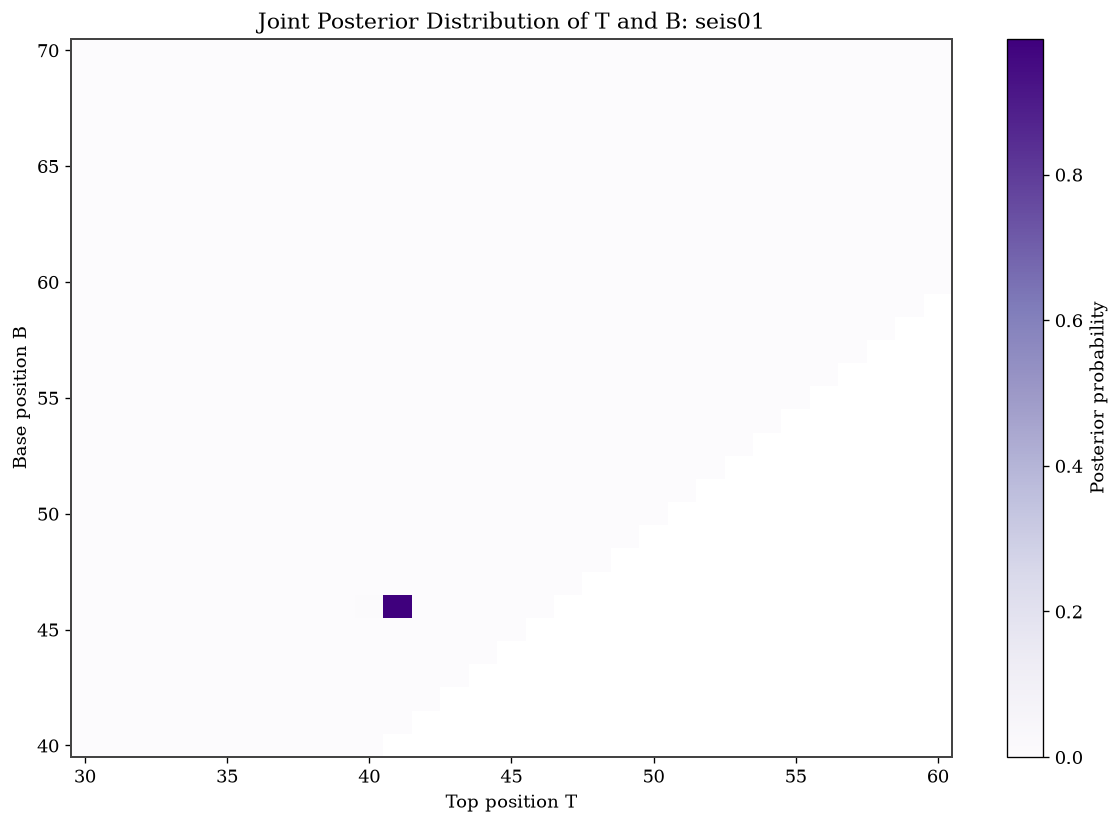

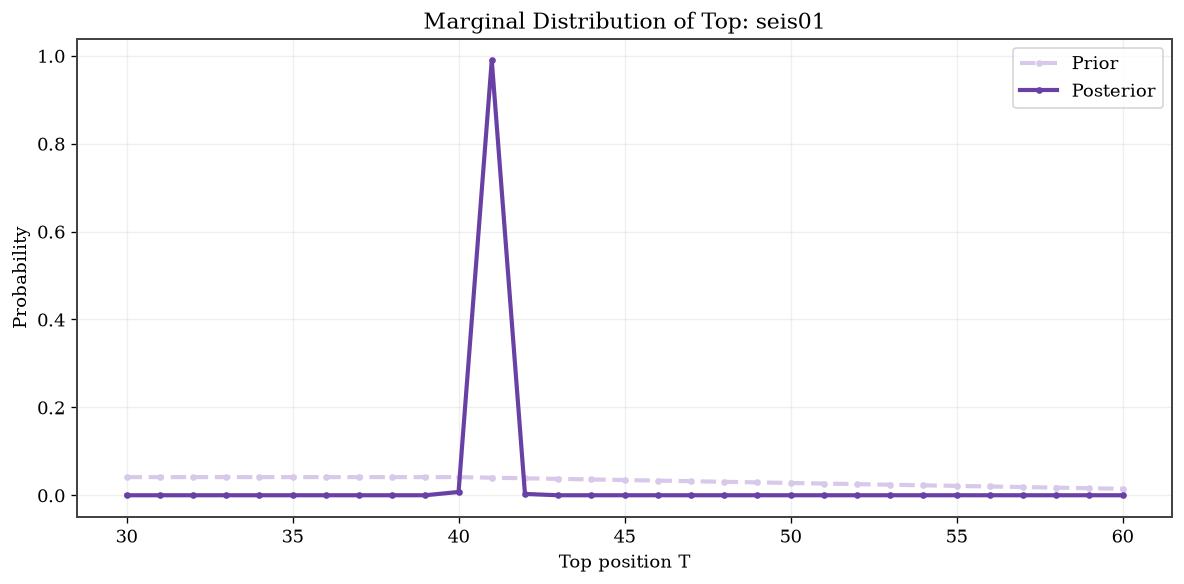

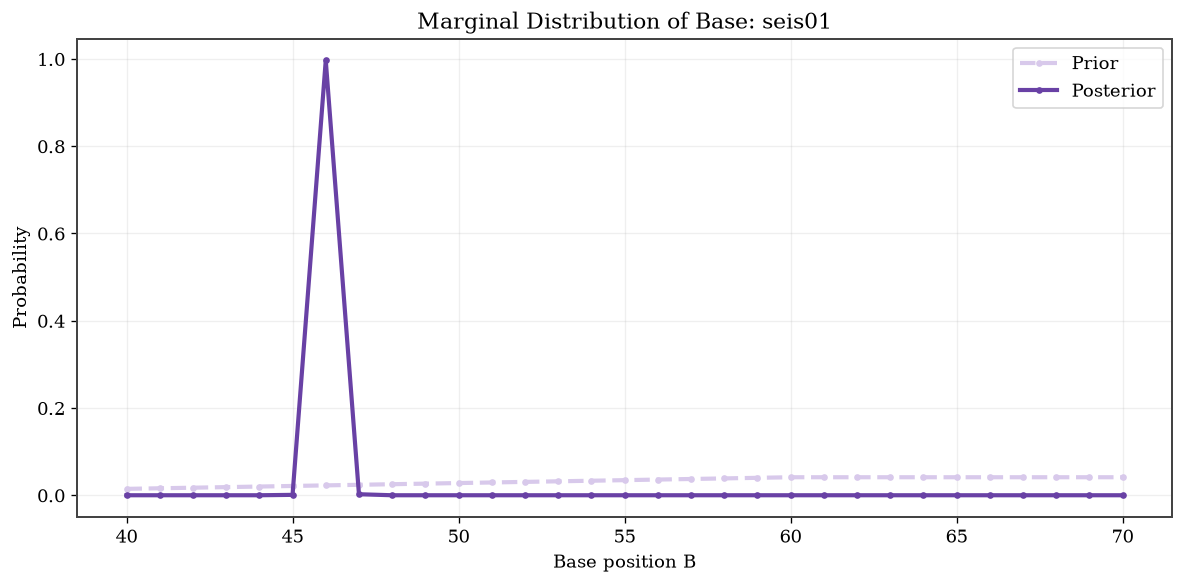

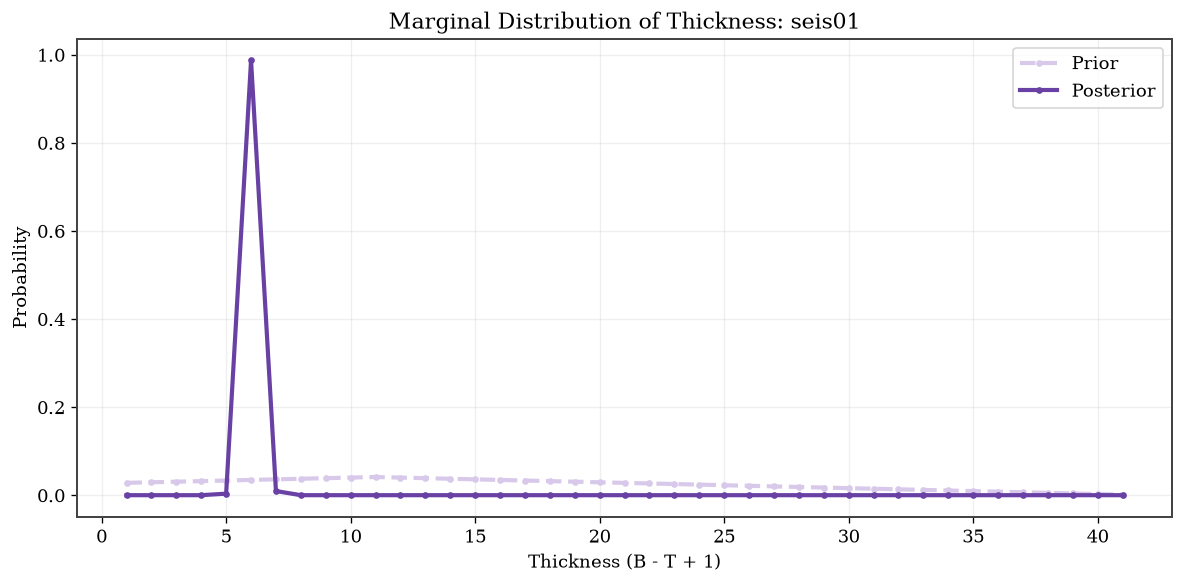

DATASET: seis02
Joint MAP top T: 41
Joint MAP base B: 61
Joint MAP thickness: 21
Marginal MAP top: 41
Marginal MAP base: 61
Marginal MAP thickness: 21
Maximum joint posterior probability: 0.994619


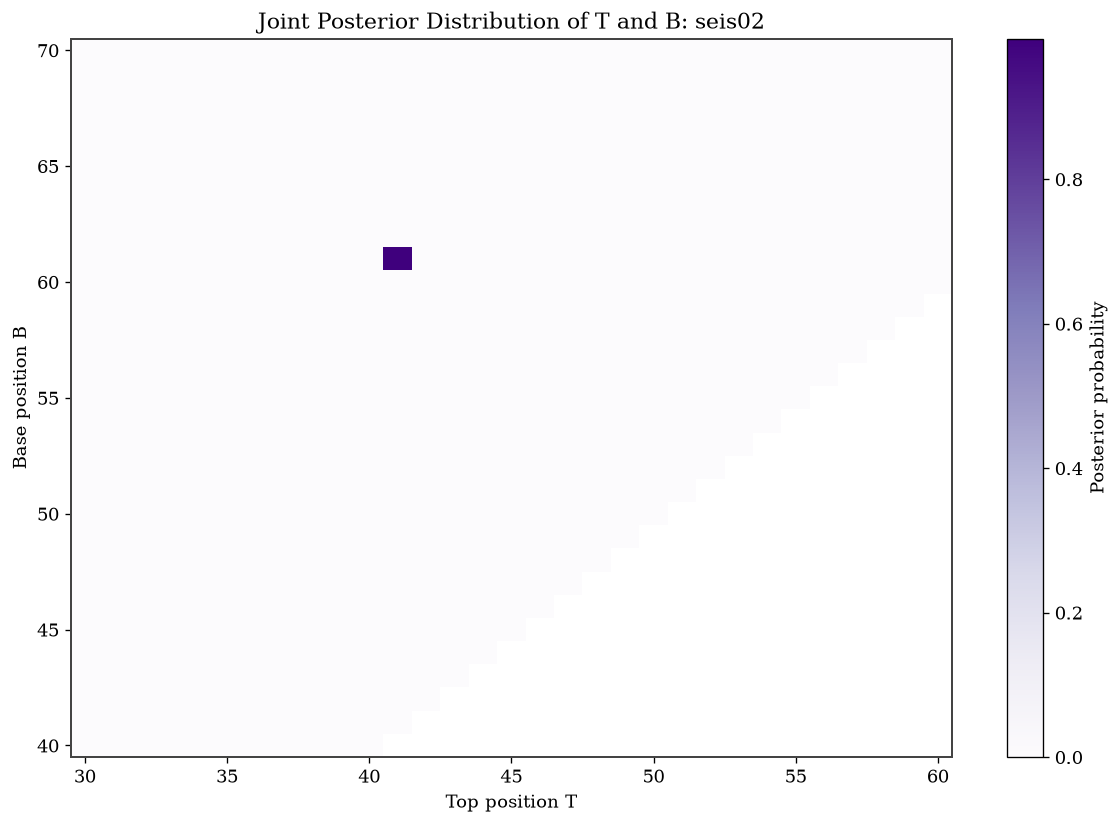

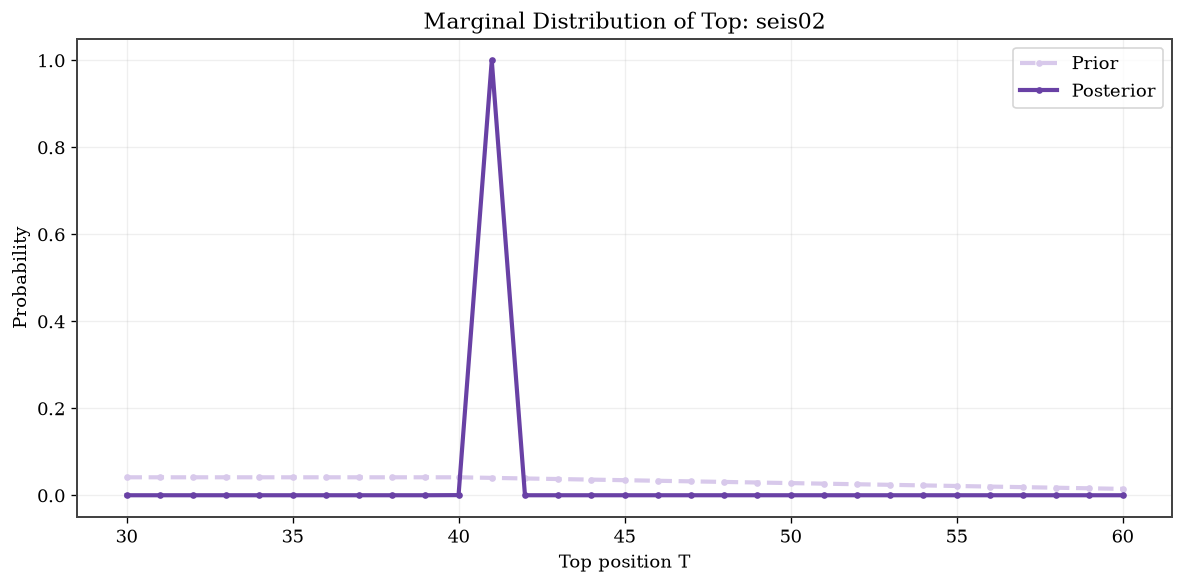

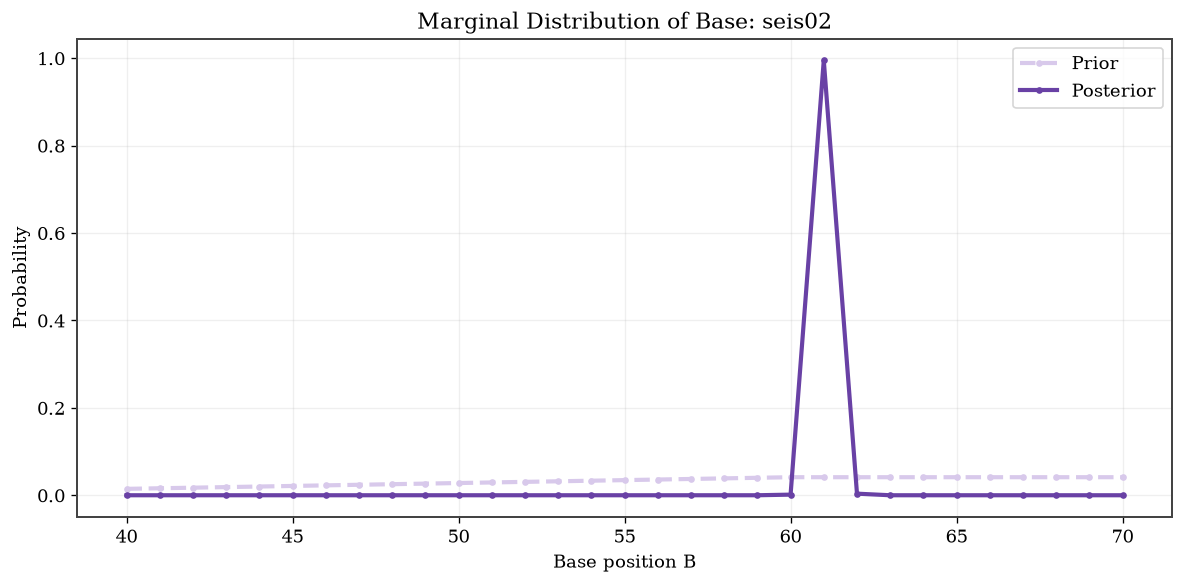

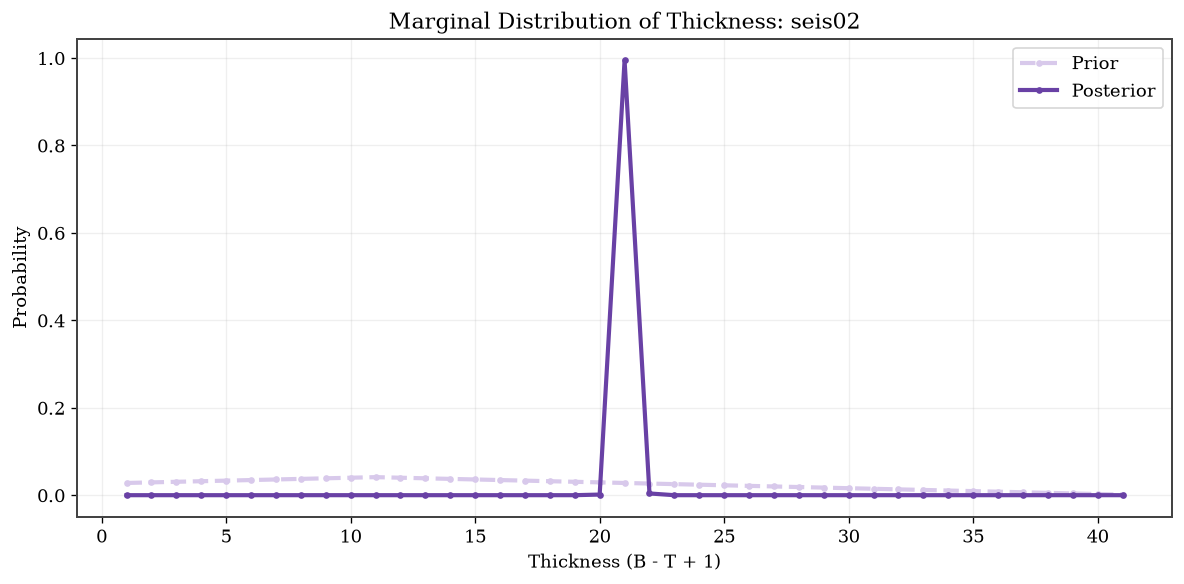

In [6]:
# 2(a)
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from pathlib import Path



n = 101

mu = 0.0
delta_mu = 5.0

sigma_m2 = 1.0
ell = 20.0
sigma_eps2 = 0.04

T_values = np.arange(30, 61)
B_values = np.arange(40, 71)

Path("figures").mkdir(exist_ok=True)

# Visualization colors
prior_color = "#D8C9EB"
posterior_color = "#6941A5"
heatmap_cmap = "Purples"



A = np.loadtxt("A.txt")

d01 = np.loadtxt("seis01.txt").reshape(-1)
d02 = np.loadtxt("seis02.txt").reshape(-1)

assert A.shape == (n, n)
assert d01.shape == (n,)
assert d02.shape == (n,)




indices = np.arange(n)

distance = np.abs(
    indices[:, None] - indices[None, :]
)

Sigma_m = sigma_m2 * np.exp(
    -3 * distance / ell
)

# Covariance of the observed data
Sigma_d = (
    A @ Sigma_m @ A.T
    + sigma_eps2 * np.eye(n)
)




pairs = [
    (T, B)
    for T in T_values
    for B in B_values
    if T <= B
]

num_pairs = len(pairs)

print("Number of admissible pairs:", num_pairs)

# Uniform prior over admissible pairs
prior_pairs = np.full(num_pairs, 1.0 / num_pairs)




mean_profiles = np.zeros((num_pairs, n))

for k, (T, B) in enumerate(pairs):

    # Convert profile positions (1,...,101)
    # to Python indices (0,...,100)
    mean_profiles[k, T - 1:B] = mu - delta_mu

# Expected seismic data for each candidate
expected_data = mean_profiles @ A.T




def calculate_posterior(d):

    # Difference between observed and expected data
    residuals = d[None, :] - expected_data

    # Mahalanobis squared distances
    solved = np.linalg.solve(Sigma_d, residuals.T)

    quadratic = np.sum(
        residuals * solved.T,
        axis=1
    )

    # Gaussian log-likelihood up to a constant
    log_likelihood = -0.5 * quadratic

    # Add uniform log-prior
    log_weights = log_likelihood + np.log(prior_pairs)

    # Normalize safely using logsumexp
    posterior_pairs = np.exp(
        log_weights - logsumexp(log_weights)
    )

    return posterior_pairs




def calculate_marginals(probabilities):

    top = np.zeros(len(T_values))
    base = np.zeros(len(B_values))

    # Possible thickness values
    thickness_values = np.arange(1, 42)
    thickness = np.zeros(len(thickness_values))

    for k, (T, B) in enumerate(pairs):

        probability = probabilities[k]

        top[T - T_values[0]] += probability
        base[B - B_values[0]] += probability

        dz = B - T + 1
        thickness[dz - 1] += probability

    return top, base, thickness


# Prior marginal distributions
prior_top, prior_base, prior_thickness = (
    calculate_marginals(prior_pairs)
)

thickness_values = np.arange(1, 42)



def rectangular_border(ax):

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#444444")
        spine.set_linewidth(1.2)




def plot_marginal(
    x,
    prior,
    posterior,
    xlabel,
    title,
    filename
):

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        x,
        prior,
        color=prior_color,
        linewidth=2.5,
        linestyle="--",
        marker="o",
        markersize=3,
        label="Prior"
    )

    ax.plot(
        x,
        posterior,
        color=posterior_color,
        linewidth=2.5,
        marker="o",
        markersize=3,
        label="Posterior"
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Probability")
    ax.set_title(title)

    ax.grid(alpha=0.2)
    ax.legend()

    rectangular_border(ax)

    fig.tight_layout()

    fig.savefig(
        f"figures/{filename}",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()




def plot_joint_posterior(posterior, dataset_name):

    # Rows correspond to B; columns correspond to T
    joint = np.full(
        (len(B_values), len(T_values)),
        np.nan
    )

    for k, (T, B) in enumerate(pairs):
        joint[B - B_values[0], T - T_values[0]] = posterior[k]

    fig, ax = plt.subplots(figsize=(10, 7))

    im = ax.imshow(
        joint,
        origin="lower",
        aspect="auto",
        cmap=heatmap_cmap,
        extent=[
            T_values[0] - 0.5,
            T_values[-1] + 0.5,
            B_values[0] - 0.5,
            B_values[-1] + 0.5
        ]
    )

    ax.set_xlabel("Top position T")
    ax.set_ylabel("Base position B")

    ax.set_title(
        f"Joint Posterior Distribution of T and B: {dataset_name}"
    )

    fig.colorbar(
        im,
        ax=ax,
        label="Posterior probability"
    )

    rectangular_border(ax)

    fig.tight_layout()

    fig.savefig(
        f"figures/joint_posterior_{dataset_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()




def analyze_dataset(d, dataset_name):

   
    print("DATASET:", dataset_name)
 

    posterior = calculate_posterior(d)

    post_top, post_base, post_thickness = (
        calculate_marginals(posterior)
    )

    # Most probable joint pair (MAP estimate)
    map_index = np.argmax(posterior)
    T_map, B_map = pairs[map_index]

    # Marginal MAP estimates
    T_marginal_map = T_values[np.argmax(post_top)]
    B_marginal_map = B_values[np.argmax(post_base)]

    thickness_map = thickness_values[
        np.argmax(post_thickness)
    ]

    print(f"Joint MAP top T: {T_map}")
    print(f"Joint MAP base B: {B_map}")
    print(f"Joint MAP thickness: {B_map - T_map + 1}")

    print(f"Marginal MAP top: {T_marginal_map}")
    print(f"Marginal MAP base: {B_marginal_map}")
    print(f"Marginal MAP thickness: {thickness_map}")

    print(
        f"Maximum joint posterior probability: "
        f"{posterior[map_index]:.6f}"
    )

    # Joint posterior heatmap
    plot_joint_posterior(posterior, dataset_name)

    # Marginal posterior for top
    plot_marginal(
        T_values,
        prior_top,
        post_top,
        "Top position T",
        f"Marginal Distribution of Top: {dataset_name}",
        f"top_marginal_{dataset_name}.png"
    )

    # Marginal posterior for base
    plot_marginal(
        B_values,
        prior_base,
        post_base,
        "Base position B",
        f"Marginal Distribution of Base: {dataset_name}",
        f"base_marginal_{dataset_name}.png"
    )

    # Marginal posterior for thickness
    plot_marginal(
        thickness_values,
        prior_thickness,
        post_thickness,
        "Thickness (B - T + 1)",
        f"Marginal Distribution of Thickness: {dataset_name}",
        f"thickness_marginal_{dataset_name}.png"
    )

    return posterior, post_top, post_base, post_thickness




results01 = analyze_dataset(d01, "seis01")
results02 = analyze_dataset(d02, "seis02")


In [7]:
# 2(b)

import numpy as np
from scipy.special import logsumexp
from scipy.linalg import cho_factor, cho_solve



P_M0 = 0.5  # Prior probability of no zone
P_M1 = 0.5  # Prior probability of a zone

assert np.isclose(P_M0 + P_M1, 1.0)



num_pairs = len(pairs)

print("Number of admissible zone pairs:", num_pairs)



chol = cho_factor(
    Sigma_d,
    lower=True,
    check_finite=True
)



def log_gaussian_kernel(residual):

    solved = cho_solve(chol, residual)

    return -0.5 * residual @ solved




def calculate_no_zone_probability(d):

    # MODEL M0: no zone, mean profile = zero
    # Expected seismic data = A @ zero = zero

    log_L0 = log_gaussian_kernel(d)

    # MODEL M1: zone with unknown boundaries
    # Compute likelihood for every admissible pair

    residuals = d[None, :] - expected_data

    solved = cho_solve(chol, residuals.T)

    quadratic = np.sum(
        residuals * solved.T,
        axis=1
    )

    log_likelihoods = -0.5 * quadratic

    # Uniform prior over all admissible zone pairs
    log_L1 = (
        logsumexp(log_likelihoods)
        - np.log(num_pairs)
    )

    # Include prior probabilities of the two models
    log_w0 = np.log(P_M0) + log_L0
    log_w1 = np.log(P_M1) + log_L1

    # Normalize safely
    log_normalizer = logsumexp([log_w0, log_w1])

    posterior_M0 = np.exp(log_w0 - log_normalizer)
    posterior_M1 = np.exp(log_w1 - log_normalizer)

    # Bayes factor: evidence for a zone vs no zone
    log_BF10 = log_L1 - log_L0

    return posterior_M0, posterior_M1, log_BF10




for dataset_name, d in [
    ("seis01", d01),
    ("seis02", d02)
]:

    p_no_zone, p_zone, log_BF10 = (
        calculate_no_zone_probability(d)
    )

    
    print("DATASET:", dataset_name)
    

    print(f"P(No zone | data) = {p_no_zone:.10f}")
    print(f"P(Zone | data)    = {p_zone:.10f}")
    print(f"Log Bayes factor (zone/no zone) = {log_BF10:.4f}")

    if p_zone > p_no_zone:
        print("More posterior support for a low-mean zone")
    else:
        print("More posterior support for no low-mean zone")


Number of admissible zone pairs: 751
DATASET: seis01
P(No zone | data) = 0.0000000206
P(Zone | data)    = 0.9999999794
Log Bayes factor (zone/no zone) = 17.6987
More posterior support for a low-mean zone
DATASET: seis02
P(No zone | data) = 0.0000000000
P(Zone | data)    = 1.0000000000
Log Bayes factor (zone/no zone) = 28.7149
More posterior support for a low-mean zone


In [8]:
#  2(c)

import numpy as np
import pandas as pd

from pathlib import Path
from scipy.linalg import cho_factor, cho_solve
from scipy.special import logsumexp




DATA_DIR = Path(".")

A = np.loadtxt(DATA_DIR / "A.txt")
d01 = np.loadtxt(DATA_DIR / "seis01.txt").reshape(-1)
d02 = np.loadtxt(DATA_DIR / "seis02.txt").reshape(-1)




n = 101

mu = 0.0
delta_mu = 5.0

sigma_m2 = 1.0
ell = 20.0
sigma_eps2 = 0.04

# Economic parameters
a = 1.0
b = 10.0

# Prior probabilities of competing models
P_M0 = 0.5   # No low-mean zone
P_M1 = 0.5   # Low-mean zone exists

assert A.shape == (n, n)
assert d01.size == n
assert d02.size == n




indices = np.arange(n)

Sigma_m = sigma_m2 * np.exp(
    -3.0
    * np.abs(indices[:, None] - indices[None, :])
    / ell
)

# Marginal covariance of seismic observations
Sigma_d = (
    A @ Sigma_m @ A.T
    + sigma_eps2 * np.eye(n)
)

# Cholesky factorization for stable calculations
chol = cho_factor(
    Sigma_d,
    lower=True,
    check_finite=True
)




T_values = np.arange(30, 61)
B_values = np.arange(40, 71)

pairs = [
    (T, B)
    for T in T_values
    for B in B_values
    if T <= B
]

num_pairs = len(pairs)

print("Number of admissible zone pairs:", num_pairs)

# Zone thickness for every admissible pair
thickness_values = np.array([
    B - T + 1 for T, B in pairs
], dtype=float)



mean_profiles = np.full(
    (num_pairs, n),
    mu,
    dtype=float
)

for k, (T, B) in enumerate(pairs):

    # T and B are 1-based subsurface positions
    mean_profiles[k, T - 1:B] = mu - delta_mu

# Expected seismic data for each zone configuration
expected_data = mean_profiles @ A.T

# Expected data under no-zone model
expected_data_no_zone = A @ np.full(n, mu)




def calculate_log_likelihoods(d):

    # No-zone model M0
    residual_no_zone = d - expected_data_no_zone

    solved_no_zone = cho_solve(
        chol,
        residual_no_zone
    )

    log_L0 = -0.5 * (
        residual_no_zone @ solved_no_zone
    )

    # Zone model M1, for every admissible (T, B)
    residuals = d[None, :] - expected_data

    solved = cho_solve(
        chol,
        residuals.T
    )

    quadratic = np.sum(
        residuals * solved.T,
        axis=1
    )

    log_likelihood_pairs = -0.5 * quadratic

    # Marginalize over all boundary pairs
    log_L1 = (
        logsumexp(log_likelihood_pairs)
        - np.log(num_pairs)
    )

    return log_L0, log_L1, log_likelihood_pairs




def calculate_model_posterior(d):

    log_L0, log_L1, log_likelihood_pairs = (
        calculate_log_likelihoods(d)
    )

    log_weight_M0 = np.log(P_M0) + log_L0
    log_weight_M1 = np.log(P_M1) + log_L1

    log_normalizer = logsumexp([
        log_weight_M0,
        log_weight_M1
    ])

    p_no_zone = np.exp(
        log_weight_M0 - log_normalizer
    )

    p_zone = np.exp(
        log_weight_M1 - log_normalizer
    )

    # Posterior over boundary pairs, conditional on M1
    posterior_pairs = np.exp(
        log_likelihood_pairs
        - logsumexp(log_likelihood_pairs)
    )

    log_BF10 = log_L1 - log_L0

    return (
        p_no_zone,
        p_zone,
        posterior_pairs,
        log_BF10
    )




def investment_analysis(d, dataset_name):

    (
        p_no_zone,
        p_zone,
        posterior_pairs,
        log_BF10
    ) = calculate_model_posterior(d)

    # Expected thickness conditional on zone existence
    expected_V_given_zone = np.sum(
        posterior_pairs * thickness_values
    )

    # Expected thickness including possibility of no zone
    expected_V = (
        p_zone * expected_V_given_zone
    )

    # Second moment of thickness
    expected_V_squared = p_zone * np.sum(
        posterior_pairs * thickness_values**2
    )

    # Posterior standard deviation
    variance_V = max(
        expected_V_squared - expected_V**2,
        0.0
    )

    sd_V = np.sqrt(variance_V)

    # Expected profit from investing
    expected_profit = a * expected_V - b

    # Posterior expected loss
    expected_loss_invest = b - a * expected_V
    expected_loss_no_invest = 0.0

    # Probability that investment produces a profit
    profitable_pairs = (
        a * thickness_values - b > 0
    )

    p_positive_profit = p_zone * np.sum(
        posterior_pairs[profitable_pairs]
    )

    # Probability of negative profit
    # No-zone case also results in a loss of -b
    losing_pairs = (
        a * thickness_values - b < 0
    )

    p_negative_profit = (
        p_no_zone
        + p_zone * np.sum(
            posterior_pairs[losing_pairs]
        )
    )

    # Bayesian decision
    if expected_loss_invest < expected_loss_no_invest:
        decision = "INVEST"

    elif expected_loss_invest > expected_loss_no_invest:
        decision = "DO NOT INVEST"

    else:
        decision = "INDIFFERENT"

    # Most probable zone configuration
    map_index = np.argmax(posterior_pairs)

    T_map, B_map = pairs[map_index]

    return {
        "Dataset": dataset_name,
        "P_no_zone": p_no_zone,
        "P_zone": p_zone,
        "MAP_top": T_map,
        "MAP_base": B_map,
        "MAP_thickness": int(thickness_values[map_index]),
        "Expected_thickness_given_zone": expected_V_given_zone,
        "Expected_thickness": expected_V,
        "Thickness_SD": sd_V,
        "Expected_profit": expected_profit,
        "Expected_loss_invest": expected_loss_invest,
        "Expected_loss_no_invest": expected_loss_no_invest,
        "P_positive_profit": p_positive_profit,
        "P_negative_profit": p_negative_profit,
        "Log_BF10": log_BF10,
        "Decision": decision
    }




results = []

for dataset_name, d in [
    ("seis01", d01),
    ("seis02", d02)
]:

    result = investment_analysis(
        d,
        dataset_name
    )

    results.append(result)

    
    print("DATASET:", dataset_name)
    

    print(
        f"P(No zone | data): "
        f"{result['P_no_zone']:.12g}"
    )

    print(
        f"P(Zone | data): "
        f"{result['P_zone']:.12g}"
    )

    print(
        f"MAP boundaries: "
        f"T={result['MAP_top']}, "
        f"B={result['MAP_base']}"
    )

    print(
        f"MAP thickness: "
        f"{result['MAP_thickness']}"
    )

    print(
        f"Expected thickness: "
        f"{result['Expected_thickness']:.6f}"
    )

    print(
        f"Thickness standard deviation: "
        f"{result['Thickness_SD']:.6f}"
    )

    print(
        f"Expected investment profit: "
        f"{result['Expected_profit']:.6f}"
    )

    print(
        f"P(Positive profit): "
        f"{result['P_positive_profit']:.6f}"
    )

    print(
        f"P(Negative profit): "
        f"{result['P_negative_profit']:.6f}"
    )

    print(
        f"Expected loss if investing: "
        f"{result['Expected_loss_invest']:.6f}"
    )

    print(
        f"Recommended decision: "
        f"{result['Decision']}"
    )




results_df = pd.DataFrame(results)

output_path = DATA_DIR / "question_2c_results.csv"

results_df.to_csv(
    output_path,
    index=False
)


print("SUMMARY:")


print(
    results_df[
        [
            "Dataset",
            "Expected_thickness",
            "Thickness_SD",
            "Expected_profit",
            "P_positive_profit",
            "Decision"
        ]
    ].to_string(index=False)
)

print(f"\nResults saved to: {output_path}")


Number of admissible zone pairs: 751
DATASET: seis01
P(No zone | data): 2.05844924047e-08
P(Zone | data): 0.999999979416
MAP boundaries: T=41, B=46
MAP thickness: 6
Expected thickness: 6.005940
Thickness standard deviation: 0.113314
Expected investment profit: -3.994060
P(Positive profit): 0.000000
P(Negative profit): 1.000000
Expected loss if investing: 3.994060
Recommended decision: DO NOT INVEST
DATASET: seis02
P(No zone | data): 3.38289452476e-13
P(Zone | data): 1
MAP boundaries: T=41, B=61
MAP thickness: 21
Expected thickness: 21.002269
Thickness standard deviation: 0.092730
Expected investment profit: 11.002269
P(Positive profit): 0.999978
P(Negative profit): 0.000022
Expected loss if investing: -11.002269
Recommended decision: INVEST
SUMMARY:
Dataset  Expected_thickness  Thickness_SD  Expected_profit  P_positive_profit      Decision
 seis01            6.005940      0.113314        -3.994060       3.147462e-07 DO NOT INVEST
 seis02           21.002269      0.092730        11.0022

Number of admissible boundary pairs: 751
QUESTION 3(a): 

Original fixed-mean model:
MAP top T: 41
MAP base B: 46
MAP thickness: 6
Joint MAP probability: 0.9867409394

Uncertain-mean model:
MAP top T: 41
MAP base B: 46
MAP thickness: 6
Joint MAP probability: 0.9867409394

Prior variance at each location:
Original: 1.0000
Updated: 1.2500

Posterior comparison:
Maximum absolute probability difference: 1.7564075194e-16
Total variation distance: 1.6995866738e-16


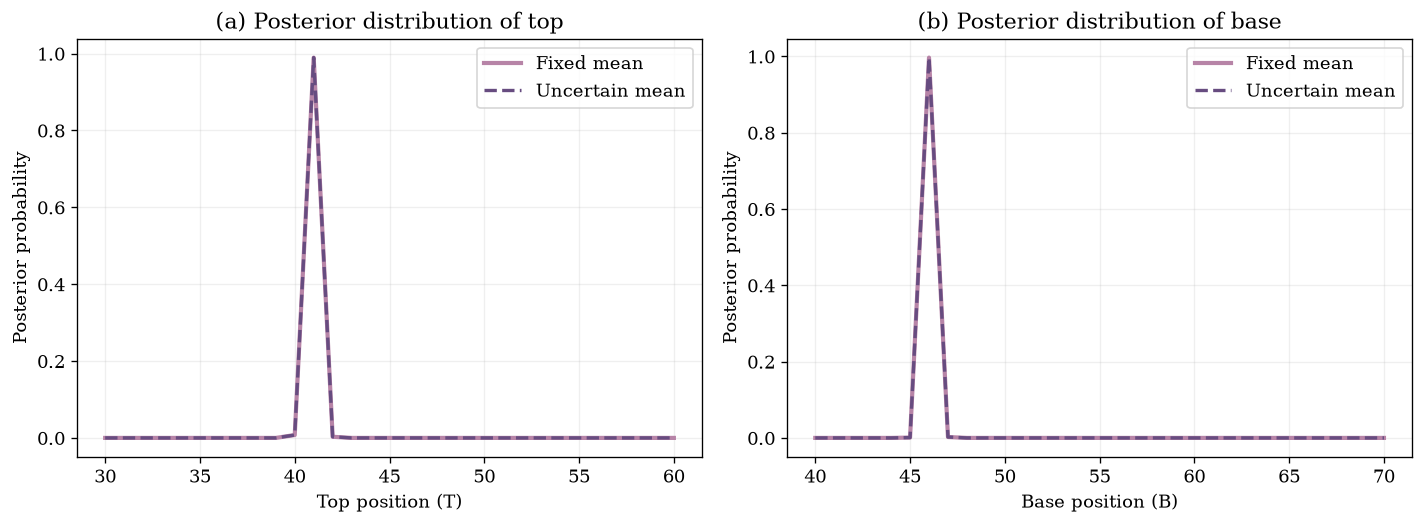

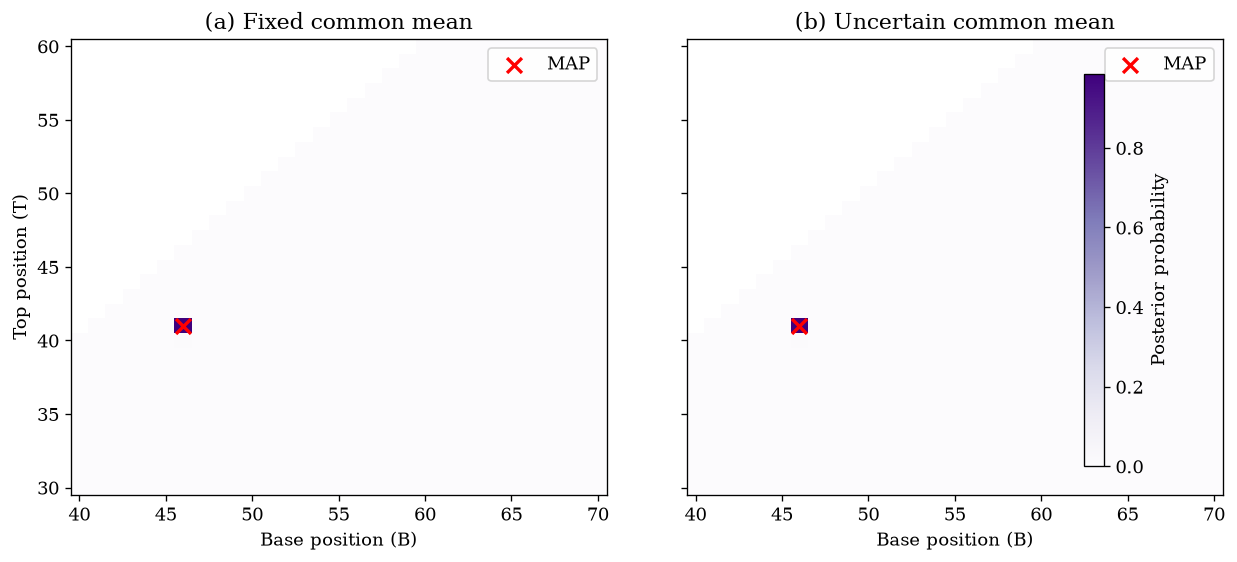

C:\Users\natab7804\Documents\STK9021 Code\figures\Q3a_Marginal_Posterior_Comparison.png
C:\Users\natab7804\Documents\STK9021 Code\figures\Q3a_Marginal_Posterior_Comparison.pdf
C:\Users\natab7804\Documents\STK9021 Code\figures\Q3a_Joint_Posterior_Heatmaps.png
C:\Users\natab7804\Documents\STK9021 Code\figures\Q3a_Joint_Posterior_Heatmaps.pdf


In [9]:

# 3(a)

import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.linalg import cho_factor, cho_solve
from scipy.special import logsumexp




DATA_DIR = Path(".")

OUTPUT_DIR = Path("Figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

A = np.loadtxt(DATA_DIR / "A.txt")
d = np.loadtxt(DATA_DIR / "seis01.txt").reshape(-1)




n = 101

sigma_m2 = 1.0
ell = 20.0
sigma_eps2 = 0.04

delta_mu = 5.0

# Uncertain common mean
mu0 = 0.0
tau_mu2 = 0.25

indices = np.arange(n)

assert A.shape == (n, n)
assert d.size == n




Sigma_m = sigma_m2 * np.exp(
    -3.0
    * np.abs(indices[:, None] - indices[None, :])
    / ell
)

ones = np.ones(n)




# Law of total covariance:
# Cov(m) = Sigma_m + tau_mu^2 * 1 * 1^T

Sigma_m_new = (
    Sigma_m
    + tau_mu2 * np.outer(ones, ones)
)

# Original observation covariance
Sigma_d_old = (
    A @ Sigma_m @ A.T
    + sigma_eps2 * np.eye(n)
)

# Updated observation covariance
Sigma_d_new = (
    A @ Sigma_m_new @ A.T
    + sigma_eps2 * np.eye(n)
)



T_values = np.arange(30, 61)
B_values = np.arange(40, 71)

pairs = [
    (T, B)
    for T in T_values
    for B in B_values
    if T <= B
]

num_pairs = len(pairs)

print("Number of admissible boundary pairs:", num_pairs)



mean_profiles = np.full(
    (num_pairs, n),
    mu0,
    dtype=float
)

for k, (T, B) in enumerate(pairs):

    # Inclusive zone boundaries (1-based indexing)
    mean_profiles[k, T-1:B] = mu0 - delta_mu

# Expected seismic data
expected_data = mean_profiles @ A.T




def calculate_posterior(covariance):

    chol = cho_factor(
        covariance,
        lower=True
    )

    residuals = d[None, :] - expected_data

    solved = cho_solve(
        chol,
        residuals.T
    )

    quadratic = np.sum(
        residuals * solved.T,
        axis=1
    )

    # Uniform prior over admissible pairs
    log_weights = -0.5 * quadratic

    posterior = np.exp(
        log_weights - logsumexp(log_weights)
    )

    return posterior


posterior_old = calculate_posterior(Sigma_d_old)
posterior_new = calculate_posterior(Sigma_d_new)




def summarize_posterior(posterior):

    map_index = np.argmax(posterior)

    T_map, B_map = pairs[map_index]

    top_marginal = np.zeros(len(T_values))
    base_marginal = np.zeros(len(B_values))

    for probability, (T, B) in zip(posterior, pairs):

        top_marginal[T - 30] += probability
        base_marginal[B - 40] += probability

    return (
        T_map,
        B_map,
        posterior[map_index],
        top_marginal,
        base_marginal
    )


(
    T_old,
    B_old,
    p_old,
    top_old,
    base_old
) = summarize_posterior(posterior_old)

(
    T_new,
    B_new,
    p_new,
    top_new,
    base_new
) = summarize_posterior(posterior_new)




print("QUESTION 3(a): ")


print("\nOriginal fixed-mean model:")
print(f"MAP top T: {T_old}")
print(f"MAP base B: {B_old}")
print(f"MAP thickness: {B_old - T_old + 1}")
print(f"Joint MAP probability: {p_old:.10f}")

print("\nUncertain-mean model:")
print(f"MAP top T: {T_new}")
print(f"MAP base B: {B_new}")
print(f"MAP thickness: {B_new - T_new + 1}")
print(f"Joint MAP probability: {p_new:.10f}")

print("\nPrior variance at each location:")
print(f"Original: {Sigma_m[0, 0]:.4f}")
print(f"Updated: {Sigma_m_new[0, 0]:.4f}")

print("\nPosterior comparison:")
print(
    "Maximum absolute probability difference:",
    f"{np.max(np.abs(posterior_new - posterior_old)):.10e}"
)

print(
    "Total variation distance:",
    f"{0.5 * np.sum(np.abs(posterior_new - posterior_old)):.10e}"
)




fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5)
)

# Top boundary T
axes[0].plot(
    T_values,
    top_old,
    color="#B784A7",
    linewidth=2.5,
    label="Fixed mean"
)

axes[0].plot(
    T_values,
    top_new,
    color="#674C80",
    linewidth=2,
    linestyle="--",
    label="Uncertain mean"
)

axes[0].set_xlabel("Top position (T)")
axes[0].set_ylabel("Posterior probability")
axes[0].set_title("(a) Posterior distribution of top")
axes[0].legend()
axes[0].grid(alpha=0.2)

# Base boundary B
axes[1].plot(
    B_values,
    base_old,
    color="#B784A7",
    linewidth=2.5,
    label="Fixed mean"
)

axes[1].plot(
    B_values,
    base_new,
    color="#674C80",
    linewidth=2,
    linestyle="--",
    label="Uncertain mean"
)

axes[1].set_xlabel("Base position (B)")
axes[1].set_ylabel("Posterior probability")
axes[1].set_title("(b) Posterior distribution of base")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()

# Save PNG
fig.savefig(
    OUTPUT_DIR / "Q3a_Marginal_Posterior_Comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

# Save PDF
fig.savefig(
    OUTPUT_DIR / "Q3a_Marginal_Posterior_Comparison.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()



def posterior_to_grid(posterior):

    grid = np.full(
        (len(T_values), len(B_values)),
        np.nan
    )

    for probability, (T, B) in zip(posterior, pairs):

        grid[T - 30, B - 40] = probability

    return grid


grid_old = posterior_to_grid(posterior_old)
grid_new = posterior_to_grid(posterior_new)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharex=True,
    sharey=True
)

# Same color scale for fair comparison
vmax = max(
    np.nanmax(grid_old),
    np.nanmax(grid_new)
)

im1 = axes[0].imshow(
    grid_old,
    origin="lower",
    aspect="auto",
    extent=[39.5, 70.5, 29.5, 60.5],
    cmap="Purples",
    vmin=0,
    vmax=vmax
)

axes[0].set_title("(a) Fixed common mean")
axes[0].set_xlabel("Base position (B)")
axes[0].set_ylabel("Top position (T)")

axes[0].scatter(
    B_old,
    T_old,
    color="red",
    marker="x",
    s=80,
    linewidths=2,
    label="MAP"
)
axes[0].legend()

im2 = axes[1].imshow(
    grid_new,
    origin="lower",
    aspect="auto",
    extent=[39.5, 70.5, 29.5, 60.5],
    cmap="Purples",
    vmin=0,
    vmax=vmax
)

axes[1].set_title("(b) Uncertain common mean")
axes[1].set_xlabel("Base position (B)")

axes[1].scatter(
    B_new,
    T_new,
    color="red",
    marker="x",
    s=80,
    linewidths=2,
    label="MAP"
)
axes[1].legend()

fig.colorbar(
    im2,
    ax=axes,
    label="Posterior probability",
    shrink=0.85,
    pad=0.03
)

fig.subplots_adjust(
    left=0.08,
    right=0.88,
    bottom=0.12,
    top=0.88,
    wspace=0.15
)

# Save PNG
fig.savefig(
    OUTPUT_DIR / "Q3a_Joint_Posterior_Heatmaps.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

# Save PDF
fig.savefig(
    OUTPUT_DIR / "Q3a_Joint_Posterior_Heatmaps.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()




for filename in [
    "Q3a_Marginal_Posterior_Comparison.png",
    "Q3a_Marginal_Posterior_Comparison.pdf",
    "Q3a_Joint_Posterior_Heatmaps.png",
    "Q3a_Joint_Posterior_Heatmaps.pdf"
]:

    filepath = OUTPUT_DIR / filename

    print(filepath.resolve())




Number of admissible pairs: 751
QUESTION 3(b):
Prior: IG(3.0, 2.0)
Prior mean: 1.000000

Posterior conditional shape: 53.5000
Posterior mean: 1.260861
Posterior SD: 0.177285
Posterior mode: 1.212881
95% credible interval: [0.960865, 1.653689]

MAP top: 41
MAP base: 46
Joint MAP probability: 0.9547743126


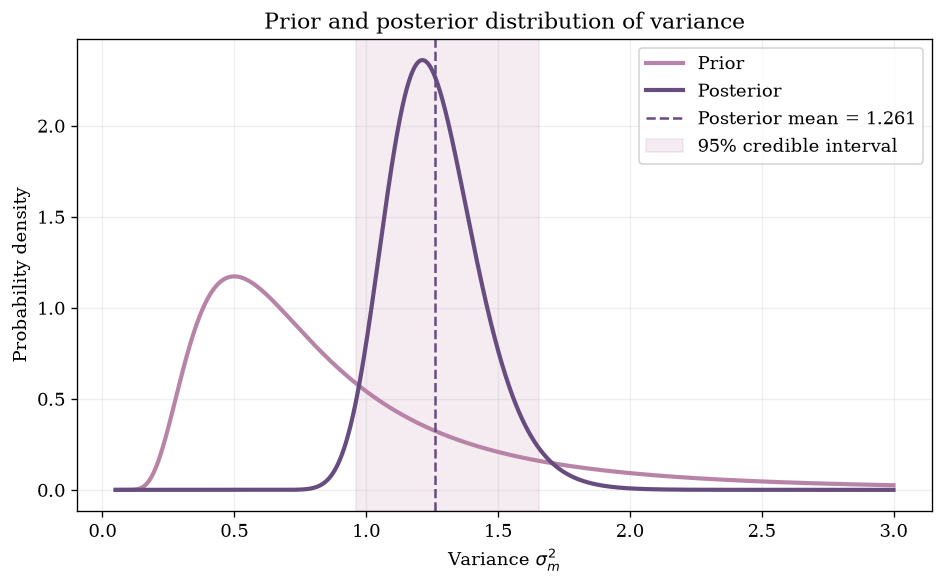


Files saved in: C:\Users\natab7804\Documents\STK9021 Code\figures


In [10]:

# 3(b)
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.linalg import cho_factor, cho_solve
from scipy.special import logsumexp
from scipy.stats import invgamma



DATA_DIR = Path(".")
OUTPUT_DIR = Path("Figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

A = np.loadtxt(DATA_DIR / "A.txt")
d = np.loadtxt(DATA_DIR / "seis01.txt").reshape(-1)

n = len(d)
assert A.shape == (n, n)



mu = 0.0
delta_mu = 5.0
ell = 20.0
nu = 0.04

# Inverse-gamma prior: IG(alpha0, beta0)
alpha0 = 3.0
beta0 = 2.0



indices = np.arange(n)

R_m = np.exp(
    -3.0 * np.abs(
        indices[:, None] - indices[None, :]
    ) / ell
)

C = A @ R_m @ A.T + nu * np.eye(n)
chol = cho_factor(C, lower=True)



T_values = np.arange(30, 61)
B_values = np.arange(40, 71)

pairs = [
    (T, B)
    for T in T_values
    for B in B_values
    if T <= B
]

num_pairs = len(pairs)
print("Number of admissible pairs:", num_pairs)



mean_profiles = np.full(
    (num_pairs, n), mu, dtype=float
)

for k, (T, B) in enumerate(pairs):
    mean_profiles[k, T-1:B] = mu - delta_mu

expected_data = mean_profiles @ A.T



residuals = d[None, :] - expected_data

solved = cho_solve(
    chol,
    residuals.T
)

Q = np.sum(
    residuals * solved.T,
    axis=1
)



alpha_n = alpha0 + n / 2.0
beta_n = beta0 + 0.5 * Q



log_weights = -alpha_n * np.log(beta_n)

posterior_pairs = np.exp(
    log_weights - logsumexp(log_weights)
)



conditional_means = beta_n / (alpha_n - 1)

conditional_variances = (
    beta_n**2 /
    ((alpha_n - 1)**2 * (alpha_n - 2))
)

posterior_mean = np.sum(
    posterior_pairs * conditional_means
)

posterior_second_moment = np.sum(
    posterior_pairs * (
        conditional_variances + conditional_means**2
    )
)

posterior_variance = (
    posterior_second_moment - posterior_mean**2
)

posterior_sd = np.sqrt(
    max(posterior_variance, 0.0)
)



s_grid = np.linspace(0.05, 3.0, 2000)

# Each row corresponds to one boundary pair
conditional_pdfs = invgamma.pdf(
    s_grid[None, :],
    a=alpha_n,
    scale=beta_n[:, None]
)

posterior_pdf = np.sum(
    posterior_pairs[:, None] * conditional_pdfs,
    axis=0
)

prior_pdf = invgamma.pdf(
    s_grid,
    a=alpha0,
    scale=beta0
)

posterior_cdf = np.sum(
    posterior_pairs[:, None] *
    invgamma.cdf(
        s_grid[None, :],
        a=alpha_n,
        scale=beta_n[:, None]
    ),
    axis=0
)



if posterior_cdf[0] > 0.025 or posterior_cdf[-1] < 0.975:
    raise ValueError(
        "Expand s_grid: posterior tails exceed grid."
    )

ci_lower = np.interp(
    0.025, posterior_cdf, s_grid
)

ci_upper = np.interp(
    0.975, posterior_cdf, s_grid
)

posterior_mode = s_grid[
    np.argmax(posterior_pdf)
]



map_index = np.argmax(posterior_pairs)
T_map, B_map = pairs[map_index]


print("QUESTION 3(b):")


print(f"Prior: IG({alpha0}, {beta0})")
print(f"Prior mean: {beta0/(alpha0-1):.6f}")

print(f"\nPosterior conditional shape: {alpha_n:.4f}")
print(f"Posterior mean: {posterior_mean:.6f}")
print(f"Posterior SD: {posterior_sd:.6f}")
print(f"Posterior mode: {posterior_mode:.6f}")

print(
    f"95% credible interval: "
    f"[{ci_lower:.6f}, {ci_upper:.6f}]"
)

print(f"\nMAP top: {T_map}")
print(f"MAP base: {B_map}")
print(
    f"Joint MAP probability: "
    f"{posterior_pairs[map_index]:.10f}"
)



fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    s_grid,
    prior_pdf,
    color="#B784A7",
    linewidth=2.5,
    label="Prior"
)

ax.plot(
    s_grid,
    posterior_pdf,
    color="#674C80",
    linewidth=2.5,
    label="Posterior"
)

ax.axvline(
    posterior_mean,
    color="#674C80",
    linestyle="--",
    linewidth=1.5,
    label=f"Posterior mean = {posterior_mean:.3f}"
)

ax.axvspan(
    ci_lower,
    ci_upper,
    color="#B784A7",
    alpha=0.15,
    label="95% credible interval"
)

ax.set_xlabel(r"Variance $\sigma_m^2$")
ax.set_ylabel("Probability density")
ax.set_title(
    "Prior and posterior distribution of variance"
)
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Q3b_Variance_Posterior.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    OUTPUT_DIR / "Q3b_Variance_Posterior.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()



results_path = OUTPUT_DIR / "Q3b_Results.txt"

with open(results_path, "w") as f:
    f.write("QUESTION 3(b): UNKNOWN VARIANCE\n")
    f.write(f"Prior: IG({alpha0}, {beta0})\n")
    f.write(f"Posterior mean: {posterior_mean:.10f}\n")
    f.write(f"Posterior SD: {posterior_sd:.10f}\n")
    f.write(f"Posterior mode: {posterior_mode:.10f}\n")
    f.write(f"95% CI: [{ci_lower:.10f}, {ci_upper:.10f}]\n")
    f.write(f"MAP T: {T_map}\n")
    f.write(f"MAP B: {B_map}\n")

print("\nFiles saved in:", OUTPUT_DIR.resolve())


Number of admissible boundary pairs: 751
QUESTION 3(c):

Fixed-scale model:
MAP top: 41
MAP base: 46
MAP probability: 0.9867409394

Uncertain-scale model:
MAP top: 41
MAP base: 46
MAP probability: 0.9547743126

Posterior comparison:
Maximum absolute difference: 0.0319666269
Total variation distance: 0.0319666269


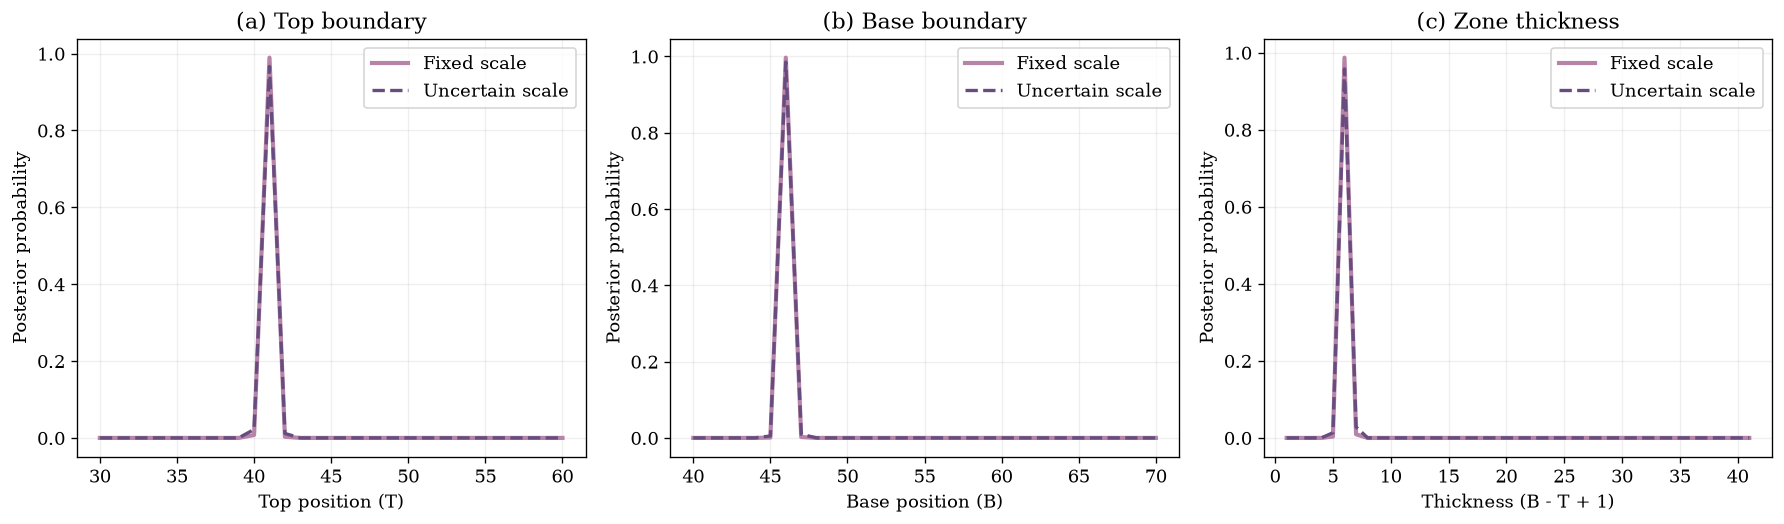

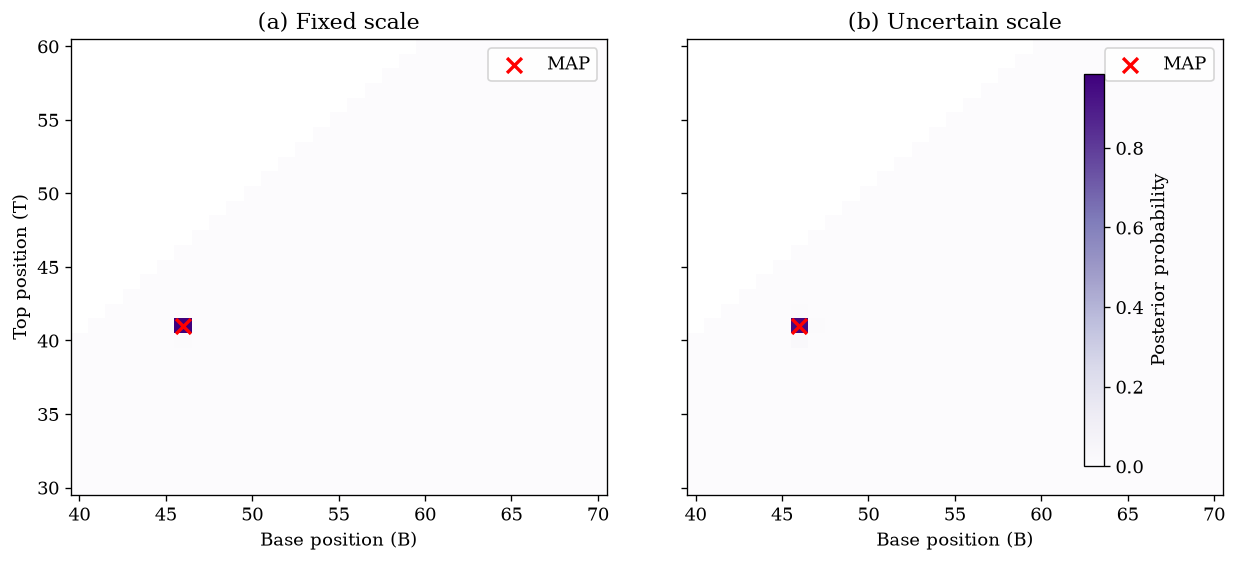


Results and figures saved in: C:\Users\natab7804\Documents\STK9021 Code\figures


In [11]:

# 3(c)

import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.linalg import cho_factor, cho_solve
from scipy.special import logsumexp



DATA_DIR = Path(".")
OUTPUT_DIR = Path("Figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

A = np.loadtxt(DATA_DIR / "A.txt")
d = np.loadtxt(DATA_DIR / "seis01.txt").reshape(-1)

n = len(d)
assert A.shape == (n, n)



mu = 0.0
delta_mu = 5.0
ell = 20.0
nu = 0.04

# Fixed-scale model
s_fixed = 1.0

# Inverse-gamma prior for uncertain scale
alpha0 = 3.0
beta0 = 2.0



indices = np.arange(n)

R_m = np.exp(
    -3.0 *
    np.abs(indices[:, None] - indices[None, :])
    / ell
)

C = A @ R_m @ A.T + nu * np.eye(n)

chol = cho_factor(C, lower=True)



T_values = np.arange(30, 61)
B_values = np.arange(40, 71)

pairs = [
    (T, B)
    for T in T_values
    for B in B_values
    if T <= B
]

num_pairs = len(pairs)

print("Number of admissible boundary pairs:", num_pairs)



mean_profiles = np.full(
    (num_pairs, n),
    mu,
    dtype=float
)

for k, (T, B) in enumerate(pairs):
    mean_profiles[k, T-1:B] = mu - delta_mu

expected_data = mean_profiles @ A.T



residuals = d[None, :] - expected_data

solved = cho_solve(
    chol,
    residuals.T
)

Q = np.sum(
    residuals * solved.T,
    axis=1
)



log_weights_fixed = -Q / (2.0 * s_fixed)

posterior_fixed = np.exp(
    log_weights_fixed
    - logsumexp(log_weights_fixed)
)



alpha_n = alpha0 + n / 2.0

beta_n = beta0 + 0.5 * Q

log_weights_uncertain = (
    -alpha_n * np.log(beta_n)
)

posterior_uncertain = np.exp(
    log_weights_uncertain
    - logsumexp(log_weights_uncertain)
)



def summarize(posterior):

    map_index = np.argmax(posterior)

    T_map, B_map = pairs[map_index]

    top_marginal = np.zeros(len(T_values))
    base_marginal = np.zeros(len(B_values))

    thickness_values = np.array([
        B - T + 1 for T, B in pairs
    ])

    unique_thickness = np.unique(thickness_values)

    thickness_marginal = np.array([
        posterior[thickness_values == v].sum()
        for v in unique_thickness
    ])

    for probability, (T, B) in zip(posterior, pairs):
        top_marginal[T - 30] += probability
        base_marginal[B - 40] += probability

    return {
        "T_map": T_map,
        "B_map": B_map,
        "MAP_probability": posterior[map_index],
        "top": top_marginal,
        "base": base_marginal,
        "thickness": thickness_marginal,
        "thickness_values": unique_thickness
    }


fixed = summarize(posterior_fixed)
uncertain = summarize(posterior_uncertain)



max_difference = np.max(
    np.abs(posterior_fixed - posterior_uncertain)
)

total_variation = 0.5 * np.sum(
    np.abs(posterior_fixed - posterior_uncertain)
)


print("QUESTION 3(c):")


print("\nFixed-scale model:")
print(f"MAP top: {fixed['T_map']}")
print(f"MAP base: {fixed['B_map']}")
print(f"MAP probability: {fixed['MAP_probability']:.10f}")

print("\nUncertain-scale model:")
print(f"MAP top: {uncertain['T_map']}")
print(f"MAP base: {uncertain['B_map']}")
print(
    f"MAP probability: "
    f"{uncertain['MAP_probability']:.10f}"
)

print("\nPosterior comparison:")
print(f"Maximum absolute difference: {max_difference:.10f}")
print(f"Total variation distance: {total_variation:.10f}")



fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5)
)

plot_settings = [
    (
        T_values,
        fixed["top"],
        uncertain["top"],
        "Top position (T)",
        "(a) Top boundary"
    ),
    (
        B_values,
        fixed["base"],
        uncertain["base"],
        "Base position (B)",
        "(b) Base boundary"
    ),
    (
        fixed["thickness_values"],
        fixed["thickness"],
        uncertain["thickness"],
        "Thickness (B - T + 1)",
        "(c) Zone thickness"
    )
]

for ax, (x, y_fixed, y_uncertain, xlabel, title) in zip(
    axes, plot_settings
):

    ax.plot(
        x,
        y_fixed,
        color="#B784A7",
        linewidth=2.5,
        label="Fixed scale"
    )

    ax.plot(
        x,
        y_uncertain,
        color="#674C80",
        linewidth=2,
        linestyle="--",
        label="Uncertain scale"
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Posterior probability")
    ax.set_title(title)
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Q3c_Marginal_Comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    OUTPUT_DIR / "Q3c_Marginal_Comparison.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()



def posterior_grid(posterior):

    grid = np.full(
        (len(T_values), len(B_values)),
        np.nan
    )

    for probability, (T, B) in zip(posterior, pairs):
        grid[T - 30, B - 40] = probability

    return grid


grid_fixed = posterior_grid(posterior_fixed)
grid_uncertain = posterior_grid(posterior_uncertain)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharex=True,
    sharey=True
)

vmax = max(
    np.nanmax(grid_fixed),
    np.nanmax(grid_uncertain)
)

for ax, grid, result, title in [
    (
        axes[0], grid_fixed, fixed,
        "(a) Fixed scale"
    ),
    (
        axes[1], grid_uncertain, uncertain,
        "(b) Uncertain scale"
    )
]:

    im = ax.imshow(
        grid,
        origin="lower",
        aspect="auto",
        extent=[39.5, 70.5, 29.5, 60.5],
        cmap="Purples",
        vmin=0,
        vmax=vmax
    )

    ax.scatter(
        result["B_map"],
        result["T_map"],
        color="red",
        marker="x",
        s=80,
        linewidths=2,
        label="MAP"
    )

    ax.set_xlabel("Base position (B)")
    ax.set_title(title)
    ax.legend()

axes[0].set_ylabel("Top position (T)")

fig.colorbar(
    im,
    ax=axes,
    label="Posterior probability",
    shrink=0.85,
    pad=0.03
)

fig.subplots_adjust(
    left=0.08,
    right=0.88,
    bottom=0.12,
    top=0.88,
    wspace=0.15
)

fig.savefig(
    OUTPUT_DIR / "Q3c_Joint_Posterior_Comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    OUTPUT_DIR / "Q3c_Joint_Posterior_Comparison.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()



results_file = OUTPUT_DIR / "Q3c_Results.txt"

with open(results_file, "w") as f:

    f.write("QUESTION 3(c): POSTERIOR COMPARISON\n\n")

    f.write("Fixed-scale model\n")
    f.write(f"T_MAP = {fixed['T_map']}\n")
    f.write(f"B_MAP = {fixed['B_map']}\n")
    f.write(
        f"MAP probability = "
        f"{fixed['MAP_probability']:.10f}\n\n"
    )

    f.write("Uncertain-scale model\n")
    f.write(f"T_MAP = {uncertain['T_map']}\n")
    f.write(f"B_MAP = {uncertain['B_map']}\n")
    f.write(
        f"MAP probability = "
        f"{uncertain['MAP_probability']:.10f}\n\n"
    )

    f.write(
        f"Maximum absolute difference = "
        f"{max_difference:.10f}\n"
    )

    f.write(
        f"Total variation distance = "
        f"{total_variation:.10f}\n"
    )

print("\nResults and figures saved in:", OUTPUT_DIR.resolve())

QUESTION 4(a):
Matrix shape: (101, 101)
Number of singular values: 101

Five largest singular values:
lambda_1 = 2.8511601507
lambda_2 = 2.8409667234
lambda_3 = 2.8132063649
lambda_4 = 2.7828584674
lambda_5 = 2.7383110852

Reconstruction error: 2.2143122326267488e-14
U orthogonality error: 1.8571911142647777e-14
V orthogonality error: 1.7946128695559576e-14


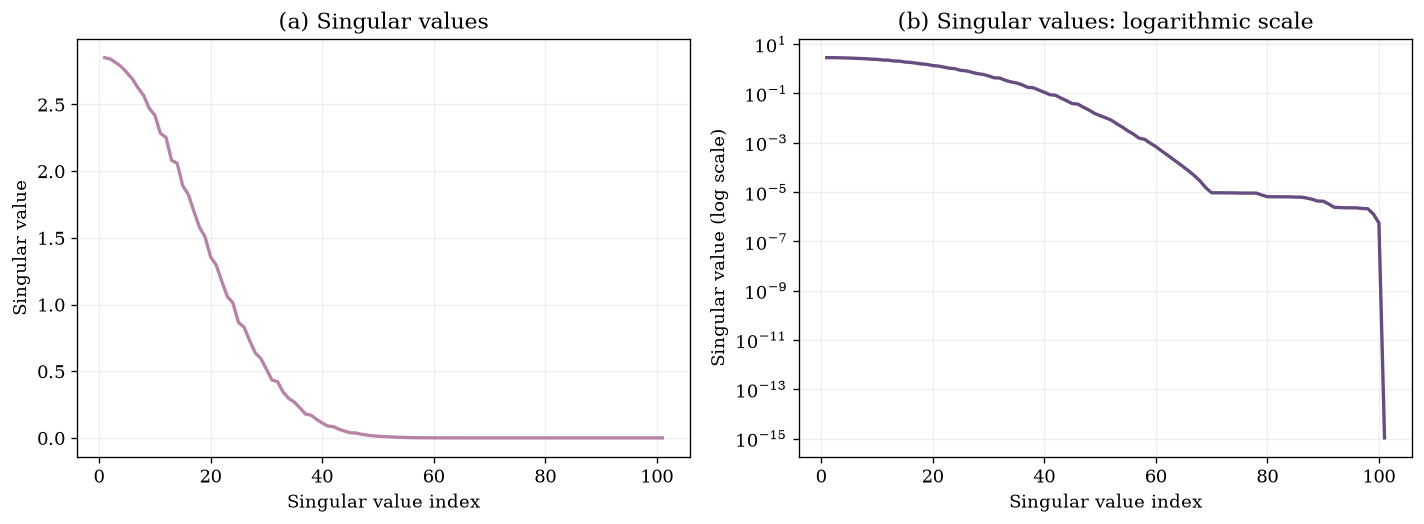

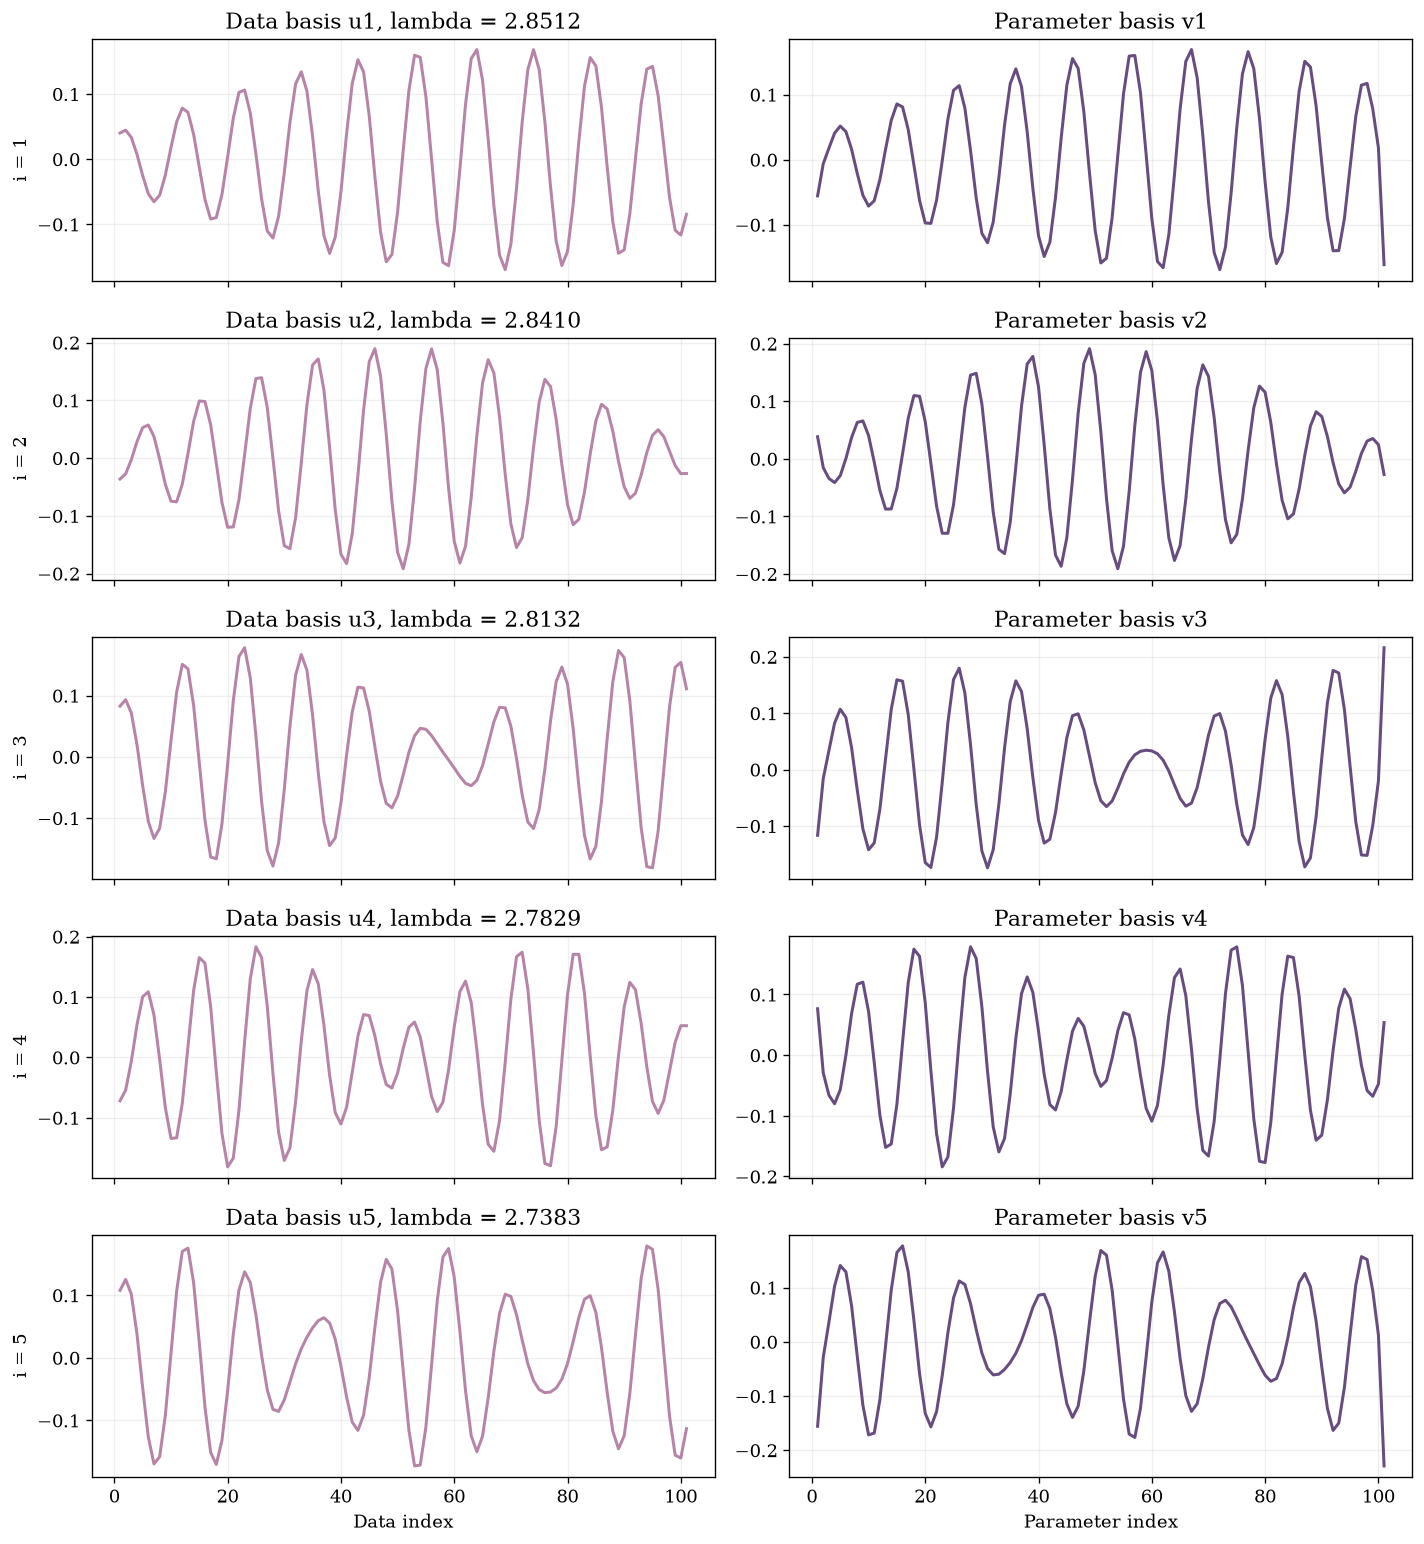


Figures saved in: C:\Users\natab7804\Documents\STK9021 Code\figures


In [12]:
# QUESTION 4(a)

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


A = np.loadtxt("A.txt")

# Output folder
output_dir = Path("Figures")
output_dir.mkdir(parents=True, exist_ok=True)

# Singular value decomposition
U, singular_values, Vt = np.linalg.svd(
    A, full_matrices=True
)

V = Vt.T

n = len(singular_values)
Lambda = np.diag(singular_values)

# Verify decomposition and orthogonality
A_reconstructed = U @ Lambda @ Vt

reconstruction_error = np.linalg.norm(
    A - A_reconstructed
)

U_error = np.linalg.norm(
    U.T @ U - np.eye(n)
)

V_error = np.linalg.norm(
    V.T @ V - np.eye(n)
)


print("QUESTION 4(a):")


print("Matrix shape:", A.shape)
print("Number of singular values:", n)

print("\nFive largest singular values:")
for i in range(5):
    print(f"lambda_{i+1} = {singular_values[i]:.10f}")

print("\nReconstruction error:", reconstruction_error)
print("U orthogonality error:", U_error)
print("V orthogonality error:", V_error)



fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

x = np.arange(1, n + 1)

axes[0].plot(
    x,
    singular_values,
    color="#B784A7",
    linewidth=2
)

axes[0].set_xlabel("Singular value index")
axes[0].set_ylabel("Singular value")
axes[0].set_title("(a) Singular values")
axes[0].grid(alpha=0.2)

axes[1].semilogy(
    x,
    singular_values,
    color="#674C80",
    linewidth=2
)

axes[1].set_xlabel("Singular value index")
axes[1].set_ylabel("Singular value (log scale)")
axes[1].set_title("(b) Singular values: logarithmic scale")
axes[1].grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    output_dir / "Q4a_Singular_Values.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    output_dir / "Q4a_Singular_Values.pdf",
    bbox_inches="tight"
)

plt.show()



fig, axes = plt.subplots(
    5, 2,
    figsize=(12, 13),
    sharex=True
)

positions = np.arange(1, n + 1)

for i in range(5):

    axes[i, 0].plot(
        positions,
        U[:, i],
        color="#B784A7",
        linewidth=1.8
    )

    axes[i, 0].set_ylabel(f"i = {i+1}")
    axes[i, 0].set_title(
        f"Data basis u{i+1}, "
        f"lambda = {singular_values[i]:.4f}"
    )
    axes[i, 0].grid(alpha=0.2)

    axes[i, 1].plot(
        positions,
        V[:, i],
        color="#674C80",
        linewidth=1.8
    )

    axes[i, 1].set_title(
        f"Parameter basis v{i+1}"
    )
    axes[i, 1].grid(alpha=0.2)

axes[-1, 0].set_xlabel("Data index")
axes[-1, 1].set_xlabel("Parameter index")

plt.tight_layout()

fig.savefig(
    output_dir / "Q4a_Leading_Basis_Pairs.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    output_dir / "Q4a_Leading_Basis_Pairs.pdf",
    bbox_inches="tight"
)

plt.show()

print("\nFigures saved in:", output_dir.resolve())


In [13]:
# 4(b)

import numpy as np


A = np.loadtxt("A.txt")
d = np.loadtxt("seis00.txt").reshape(-1)

# SVD
U, singular_values, Vt = np.linalg.svd(
    A, full_matrices=True
)

V = Vt.T

# Transform observations
d_tilde = U.T @ d


d_reconstructed = U @ d_tilde


A_tilde = U.T @ A @ V

Lambda = np.diag(singular_values)

diagonalization_error = np.linalg.norm(
    A_tilde - Lambda
)

reconstruction_error = np.linalg.norm(
    d - d_reconstructed
)

# Verify transformed error covariance
sigma_eps2 = 0.04

Sigma_eps = sigma_eps2 * np.eye(len(d))

Sigma_eps_tilde = U.T @ Sigma_eps @ U

covariance_error = np.linalg.norm(
    Sigma_eps_tilde - sigma_eps2 * np.eye(len(d))
)


print("QUESTION 4(b):")


print(
    f"Forward matrix diagonalization error: "
    f"{diagonalization_error:.12e}"
)

print(
    f"Data reconstruction error: "
    f"{reconstruction_error:.12e}"
)

print(
    f"Transformed noise covariance error: "
    f"{covariance_error:.12e}"
)

print("\nFirst five singular values:")
for i in range(5):
    print(
        f"lambda_{i+1} = "
        f"{singular_values[i]:.8f}"
    )

print("\nFirst five transformed observations:")
for i in range(5):
    print(
        f"d_tilde_{i+1} = "
        f"{d_tilde[i]:.8f}"
    )

print("\nTransformed noise covariance (first 5x5):")
print(np.round(Sigma_eps_tilde[:5, :5], 8))


QUESTION 4(b):
Forward matrix diagonalization error: 1.912379098415e-14
Data reconstruction error: 1.618460523281e-14
Transformed noise covariance error: 7.344079904398e-16

First five singular values:
lambda_1 = 2.85116015
lambda_2 = 2.84096672
lambda_3 = 2.81320636
lambda_4 = 2.78285847
lambda_5 = 2.73831109

First five transformed observations:
d_tilde_1 = -0.17758799
d_tilde_2 = 0.01818907
d_tilde_3 = -2.66110637
d_tilde_4 = -3.51338459
d_tilde_5 = -1.60461182

Transformed noise covariance (first 5x5):
[[ 0.04 -0.   -0.    0.   -0.  ]
 [-0.    0.04  0.    0.   -0.  ]
 [-0.    0.    0.04 -0.   -0.  ]
 [ 0.    0.   -0.    0.04  0.  ]
 [-0.   -0.    0.    0.    0.04]]
